# EN4554 Deep Learning for Vision — Assignment 2: CNNs on CIFAR-10

**Name:** Hathurusingha HAR &nbsp;|&nbsp; **Index:** 220221B  
**GitHub:** https://github.com/achintha-hathurusingha/en4554-a02-cnns

**Use of AI tools.** I used Claude to help write and debug code and to draft explanations. I ran every experiment myself and I have reviewed and understood all code and text.

## 0 · Setup

**How this works**
- One config cell holds every switch. `RUN_TRAINING = False` rebuilds all plots and tables from the saved JSON histories, so a Colab disconnect never forces retraining.
- Results go to Google Drive on Colab and to `./results` elsewhere. The code is device-agnostic: it uses CUDA when available, otherwise the CPU.
- `seed_everything` seeds Python, NumPy and PyTorch (CPU and every GPU), and returns a seeded generator used for mini-batch shuffling.

In [1]:
import os, sys, io, copy, json, math, time, random, platform, warnings, contextlib
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "retina"

RUN_TRAINING = True    # False: never train; rebuild every plot/table from saved JSON histories
FORCE_RETRAIN = False  # True: retrain even when a saved history exists
SEED = 0

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/en4554_a2")
    DATA_DIR = Path("/content/data")                 # Colab's local disk is faster than Drive
else:
    ROOT = Path(os.environ.get("A2_ROOT", ".")).resolve()
    DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
CKPT_DIR = RESULTS_DIR / "ckpt"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"                          # mixed precision only on a GPU
DEVICE_NAME = torch.cuda.get_device_name(0) if AMP else (platform.processor() or "CPU")
warnings.filterwarnings("ignore", message=r"Detected call of `lr_scheduler\.step\(\)`")

print(f"Python {platform.python_version()} | torch {torch.__version__} | "
      f"torchvision {torchvision.__version__}")
print(f"device: {DEVICE_NAME} | AMP: {AMP} | results -> {RESULTS_DIR}")

Python 3.12.3 | torch 2.5.1+cu124 | torchvision 0.20.1+cu124
device: Quadro RTX 5000 | AMP: True | results -> /mnt/minura/minura/en4554-a2/results


In [2]:
def seed_everything(seed=SEED):
    """Seed Python, NumPy and PyTorch (CPU + all GPUs); return a generator for shuffling."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    return torch.Generator().manual_seed(seed)

torch.backends.cudnn.benchmark = True   # fastest conv algorithms; reruns may differ in last digits
seed_everything()

# one colour per method, reused in every figure (Okabe-Ito palette, colour-blind safe)
COLORS = {"train": "#0072B2", "val": "#E69F00",
          "SGD": "#0072B2", "SGD+momentum": "#E69F00", "Adam": "#009E73",
          "sigmoid": "#CC79A7", "ReLU": "#56B4E9",
          "plain": "#999999", "residual": "#0072B2"}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.fontsize": 8.5, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
})

## 1 · Data: seeded 45k / 5k split and training-split normalisation

**How this works**
- A seeded `randperm` of the 50,000 training images gives the 45k training and 5k validation indices. The same seed always gives the same split, on any machine.
- Per-channel mean and std are computed on the **45k training split only**, so the validation split never leaks into preprocessing: $\hat x_c = (x_c/255 - \mu_c)/\sigma_c$.
- The normalised tensors live on the GPU (45k × 3 × 32 × 32 float32 = 553 MB). `batches()` slices them with a seeded permutation. This shuffles the same way as `DataLoader(shuffle=True, generator=g)` but avoids a CPU data-loading bottleneck.
- The test set is not loaded here. It is used once, in Task 4.

In [3]:
train_set = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
CLASSES = train_set.classes
X_all = torch.from_numpy(train_set.data).permute(0, 3, 1, 2).contiguous()  # uint8 (50000,3,32,32)
y_all = torch.tensor(train_set.targets)

perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45_000], perm[45_000:]
X_tr_u8, y_tr = X_all[tr_idx], y_all[tr_idx]
X_va_u8, y_va = X_all[va_idx], y_all[va_idx]

x01 = X_tr_u8.float().div_(255)                      # training split only, scaled to [0, 1]
MEAN, STD = x01.mean(dim=(0, 2, 3)), x01.std(dim=(0, 2, 3))
del x01

print(f"train {tuple(X_tr_u8.shape)} | val {tuple(X_va_u8.shape)} | shared indices: "
      f"{len(set(tr_idx.tolist()) & set(va_idx.tolist()))}")
print("channel mean (R, G, B):", MEAN.numpy().round(4), "| channel std:", STD.numpy().round(4))

Files already downloaded and verified


train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | shared indices: 0
channel mean (R, G, B): [0.4912 0.482  0.4464] | channel std: [0.2472 0.2436 0.2617]


In [4]:
def normalize(x_u8):
    """uint8 images -> float32 with zero mean / unit std per channel (training-split statistics)."""
    return (x_u8.float().div(255) - MEAN.view(1, 3, 1, 1)) / STD.view(1, 3, 1, 1)

X_tr, X_va = normalize(X_tr_u8).to(DEVICE), normalize(X_va_u8).to(DEVICE)
y_tr, y_va = y_tr.to(DEVICE), y_va.to(DEVICE)

def batches(X, y, batch_size, shuffle=False, gen=None):
    """Yield (x, y) mini-batches; shuffling uses the seeded CPU generator `gen`."""
    order = torch.randperm(len(X), generator=gen) if shuffle else torch.arange(len(X))
    order = order.to(X.device)
    for i in range(0, len(X), batch_size):
        idx = order[i:i + batch_size]
        yield X[idx], y[idx]

print(f"on {DEVICE}: X_tr {tuple(X_tr.shape)}, X_va {tuple(X_va.shape)}")
print("normalised train split, per-channel mean:", X_tr.mean((0, 2, 3)).cpu().numpy().round(3),
      "| std:", X_tr.std((0, 2, 3)).cpu().numpy().round(3))
print("normalised val split,   per-channel mean:", X_va.mean((0, 2, 3)).cpu().numpy().round(3),
      "| std:", X_va.std((0, 2, 3)).cpu().numpy().round(3))

on cuda: X_tr (45000, 3, 32, 32), X_va (5000, 3, 32, 32)
normalised train split, per-channel mean: [0. 0. 0.] | std: [1. 1. 1.]
normalised val split,   per-channel mean: [0.008 0.007 0.004] | std: [0.995 0.994 0.997]


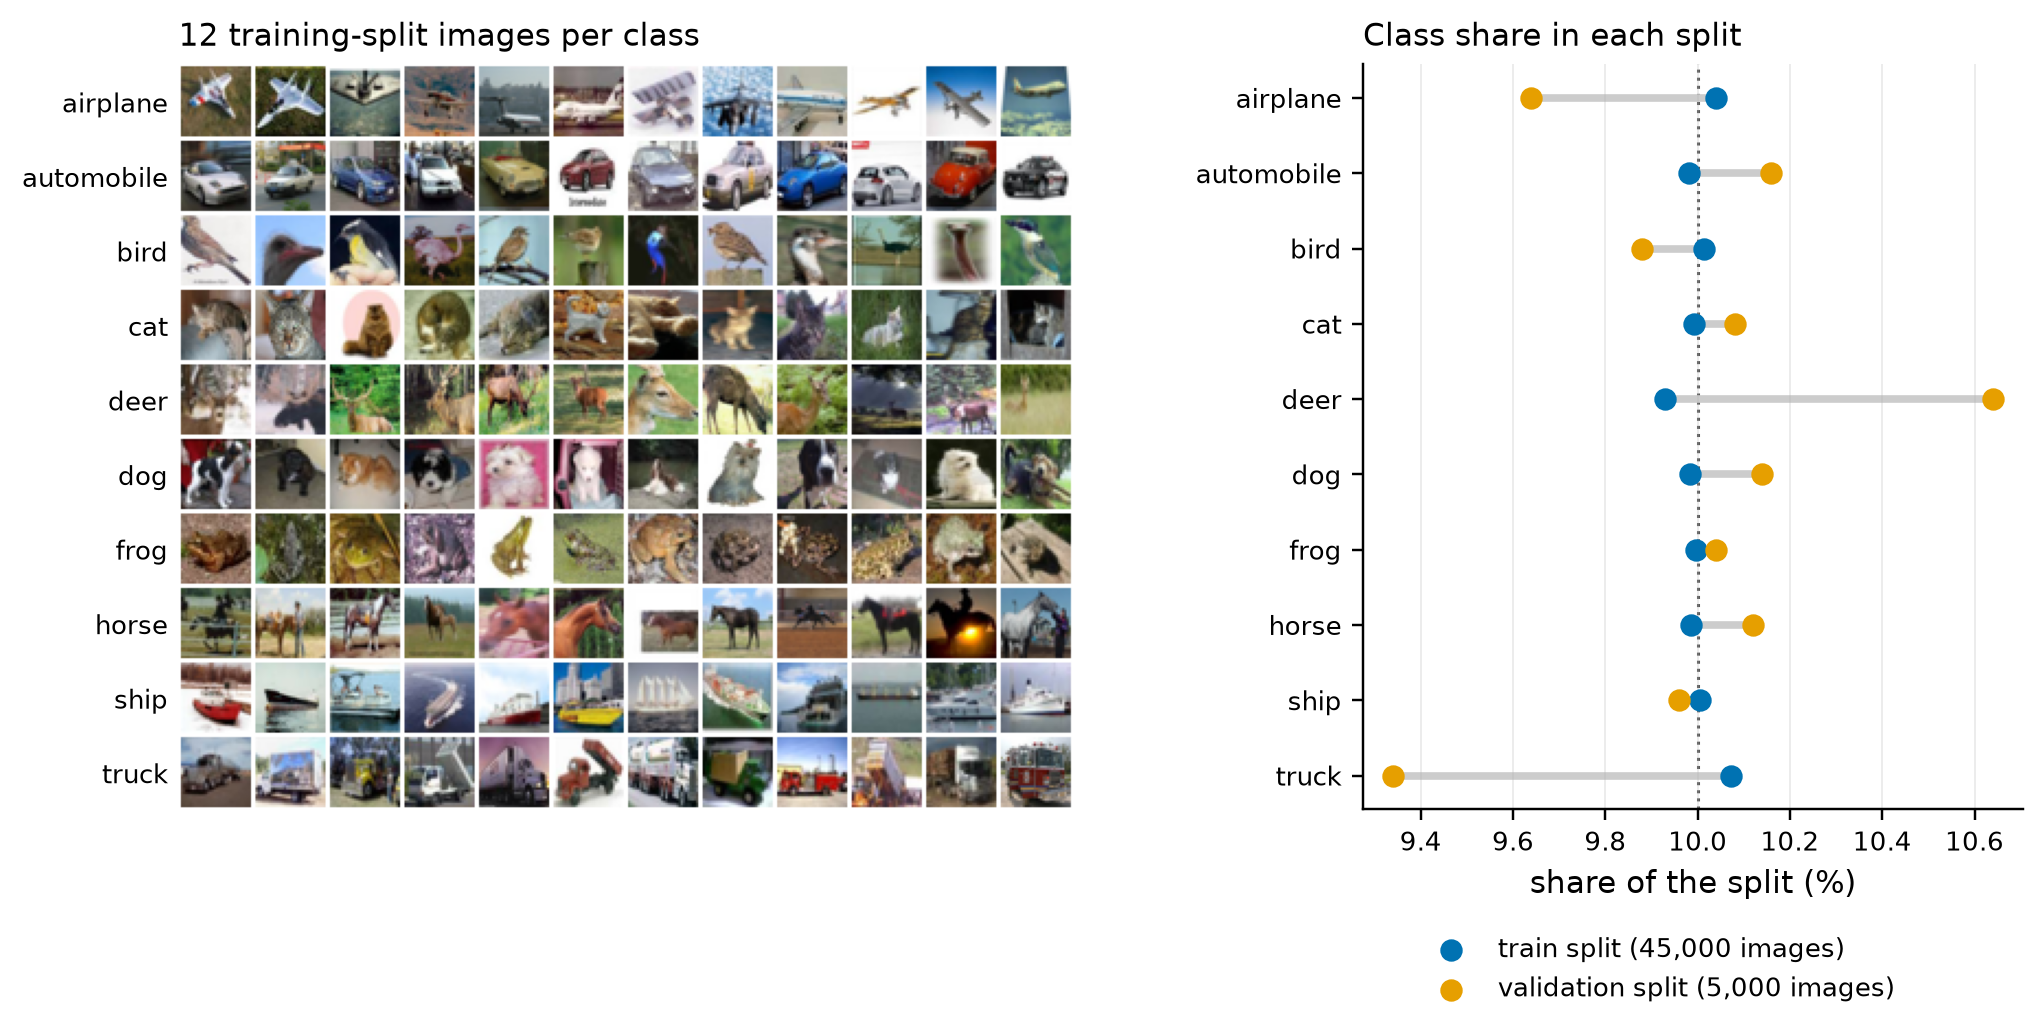

class counts  train: [4518, 4492, 4506, 4496, 4468, 4493, 4498, 4494, 4502, 4533]
              val:   [482, 508, 494, 504, 532, 507, 502, 506, 498, 467]


In [5]:
fig, (ax_img, ax_bal) = plt.subplots(1, 2, figsize=(11, 4.4),
                                     gridspec_kw={"width_ratios": [1.45, 1], "wspace": 0.32})

# left: a strip of 12 training-split images per class
y_cpu, n_show = y_tr.cpu(), 12
rows = []
for c in range(10):
    idx = (y_cpu == c).nonzero().flatten()[:n_show]
    rows.append(torch.cat([F.pad(X_tr_u8[i], (1, 1, 1, 1), value=255) for i in idx], dim=2))
ax_img.imshow(torch.cat(rows, dim=1).permute(1, 2, 0).numpy())
ax_img.set_yticks([34 * c + 17 for c in range(10)], CLASSES)
ax_img.set_xticks([]); ax_img.grid(False); ax_img.tick_params(length=0)
for s in ax_img.spines.values():
    s.set_visible(False)
ax_img.set_title(f"{n_show} training-split images per class")

# right: share of each class in the two splits (perfect balance = the dotted 10 % line)
share = lambda y: (torch.bincount(y.cpu(), minlength=10) / len(y) * 100).numpy()
s_tr, s_va, ypos = share(y_tr), share(y_va), np.arange(10)
ax_bal.hlines(ypos, np.minimum(s_tr, s_va), np.maximum(s_tr, s_va), color="0.8", lw=2.5, zorder=1)
ax_bal.scatter(s_tr, ypos, color=COLORS["train"], s=40, zorder=3,
               label=f"train split ({len(y_tr):,} images)")
ax_bal.scatter(s_va, ypos, color=COLORS["val"], s=40, zorder=3,
               label=f"validation split ({len(y_va):,} images)")
ax_bal.axvline(10, color="0.35", ls=":", lw=1, zorder=0)
ax_bal.set_yticks(ypos, CLASSES); ax_bal.invert_yaxis(); ax_bal.grid(axis="y", visible=False)
ax_bal.set_xlabel("share of the split (%)")
ax_bal.set_title("Class share in each split")
ax_bal.legend(loc="upper center", bbox_to_anchor=(0.45, -0.14), ncol=1)
plt.show()

print("class counts  train:", torch.bincount(y_tr.cpu(), minlength=10).tolist())
print("              val:  ", torch.bincount(y_va.cpu(), minlength=10).tolist())

**Interpretation.** The split is random, not stratified, yet every class stays close to 10 %. Training counts run from 4,468 (deer) to 4,533 (truck), and validation counts from 467 (truck, 9.34 %) to 532 (deer, 10.64 %). The validation split scatters more only because it is nine times smaller: a binomial count of 5,000 × 0.1 has std ≈ 21 images, so the largest deviation (33) is ordinary sampling noise, too small to bias later validation accuracies. After normalising with training statistics (R/G/B mean 0.491/0.482/0.446, std 0.247/0.244/0.262), the training split has mean 0 and std 1 by construction. The validation split sits at means ≤ 0.008 and stds 0.994–0.997, the small offset expected when validation data never enter preprocessing.

## Shared training loop (used by Tasks 2–4)

**How this works**
- `train_one_epoch` runs the forward pass under `torch.autocast` (float16 convolutions and matrix multiplies on the GPU's tensor cores; reductions such as the loss stay in float32).
- `GradScaler` backpropagates $S\cdot L$ instead of $L$ so that small float16 gradients don't underflow to zero. It divides the gradients by $S$ before the update, and skips the step and halves $S$ if any gradient is inf/NaN.
- `evaluate` uses `model.eval()`: batch norm uses its running statistics and dropout is off.
- `run_experiment` trains one configuration and saves its history (losses, accuracies, seconds per epoch) to `results/<name>.json` straight after the run. If the file already exists, it loads it instead of retraining. A loss that becomes inf/NaN stops the run and marks it `diverged`.

In [6]:
def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, X, y, batch_size=1000):
    """Mean cross-entropy and accuracy on (X, y) in eval mode."""
    model.eval()
    loss_sum = torch.zeros((), device=X.device)
    correct = torch.zeros((), device=X.device)
    for xb, yb in batches(X, y, batch_size):
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            logits = model(xb)
        loss_sum += F.cross_entropy(logits.float(), yb, reduction="sum")
        correct += (logits.argmax(1) == yb).sum()
    return loss_sum.item() / len(X), correct.item() / len(X)

def train_one_epoch(model, opt, scaler, X, y, gen, batch_size=128, sched=None,
                    augment=None, mix_fn=None, label_smoothing=0.0):
    """One pass over (X, y); returns the mean training loss on the (augmented) batches."""
    model.train()
    loss_sum, n = torch.zeros((), device=X.device), 0
    for xb, yb in batches(X, y, batch_size, shuffle=True, gen=gen):
        if augment is not None:
            xb = augment(xb)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            if mix_fn is None:
                loss = F.cross_entropy(model(xb), yb, label_smoothing=label_smoothing)
            else:                         # mixup: the loss mixes the two labels like the images
                xb, ya, yb2, lam = mix_fn(xb, yb)
                logits = model(xb)
                loss = lam * F.cross_entropy(logits, ya) + (1 - lam) * F.cross_entropy(logits, yb2)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()     # backprop S*L so fp16 gradients don't underflow
        scaler.step(opt)                  # unscale, then step (skipped if a grad is inf/NaN)
        scaler.update()
        if sched is not None:
            sched.step()                             # schedules here step once per mini-batch
        loss_sum += loss.detach() * len(xb)
        n += len(xb)
    return loss_sum.item() / n

In [7]:
def run_experiment(name, make_model, make_opt, epochs, X=None, y=None, batch_size=128,
                   make_sched=None, augment=None, mix_fn=None, label_smoothing=0.0,
                   eval_train=None, seed=SEED, save_model=False, log_every=None):
    """Train one configuration (or load its saved history) and return the per-epoch history dict."""
    path = RESULTS_DIR / f"{name}.json"
    if path.exists() and not FORCE_RETRAIN:
        h = json.loads(path.read_text())
        print(f"[loaded] {name}: val acc {h['val_acc'][-1]:.2%} after {len(h['val_acc'])} epochs, "
              f"{np.mean(h['epoch_time']):.1f} s/epoch on {h['device']}")
        return h
    if not RUN_TRAINING:
        raise FileNotFoundError(f"{path} is missing and RUN_TRAINING is False")
    X = X_tr if X is None else X
    y = y_tr if y is None else y
    gen = seed_everything(seed)                      # same seed -> same init, same batch order
    model = make_model().to(DEVICE)
    opt = make_opt(model.parameters())
    sched = make_sched(opt, epochs * math.ceil(len(X) / batch_size)) if make_sched else None
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP)
    h = {"name": name, "params": n_params(model), "device": DEVICE_NAME, "seed": seed,
         "diverged": False,
         "train_loss": [], "val_loss": [], "val_acc": [], "train_acc": [], "epoch_time": []}
    log_every = log_every or max(1, epochs // 5)
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        tl = train_one_epoch(model, opt, scaler, X, y, gen, batch_size, sched,
                             augment, mix_fn, label_smoothing)
        if AMP:
            torch.cuda.synchronize()
        h["epoch_time"].append(time.perf_counter() - t0)
        vl, va = evaluate(model, X_va, y_va)
        h["train_loss"].append(tl); h["val_loss"].append(vl); h["val_acc"].append(va)
        if eval_train is not None:                   # e.g. clean (un-augmented) training images
            h["train_acc"].append(evaluate(model, *eval_train)[1])
        diverged = not math.isfinite(tl)
        if ep == 1 or ep % log_every == 0 or diverged:
            print(f"{name} | epoch {ep:>3}/{epochs} | train loss {tl:.4f} | val loss {vl:.4f} | "
                  f"val acc {va:.2%} | {h['epoch_time'][-1]:.1f} s/epoch")
        if diverged:
            h["diverged"] = True
            print(f"{name}: training loss is not finite -> run stopped (diverged)")
            break
    path.write_text(json.dumps(h))
    if save_model:
        torch.save(model.state_dict(), CKPT_DIR / f"{name}.pt")
    return h

def load_history(name):
    return json.loads((RESULTS_DIR / f"{name}.json").read_text())

## Task 1 · Backpropagation by hand (L06)

### (a) Linear, ReLU, sigmoid and softmax cross-entropy with explicit forward/backward

**How this works**
- Each layer caches what its backward pass needs. `backward(g)` receives $g=\partial L/\partial(\text{output})$ and returns $\partial L/\partial(\text{input})$, which is the chain rule applied one layer at a time. No autograd is used.
- Linear, $y = xW + b$ with $x\in\mathbb{R}^{N\times D}$, $W\in\mathbb{R}^{D\times M}$:
  $\quad \dfrac{\partial L}{\partial W} = x^\top g,\qquad \dfrac{\partial L}{\partial b} = \sum_{n} g_n,\qquad \dfrac{\partial L}{\partial x} = g\,W^\top$
- ReLU: $\partial L/\partial x = g\odot\mathbb{1}[x>0]$ (the mask). Sigmoid: $\partial L/\partial x = g\odot\sigma(x)(1-\sigma(x))$.
- Softmax cross-entropy: $p=\mathrm{softmax}(z)$, $L=-\frac1N\sum_n \log p_{n,y_n}$, so $\dfrac{\partial L}{\partial z} = \dfrac{p - Y}{N}$ with $Y$ one-hot. Subtracting $\max_j z_j$ first leaves $p$ unchanged and prevents `exp` overflow.

In [8]:
class Linear:
    """y = x @ W + b, W of shape (d_in, d_out). Caches x for the backward pass."""
    def __init__(self, d_in, d_out, init="kaiming", dtype=torch.float32, device=DEVICE):
        std = math.sqrt(2 / d_in) if init == "kaiming" else math.sqrt(2 / (d_in + d_out))
        self.W = (torch.randn(d_in, d_out, dtype=torch.float64) * std).to(device, dtype)
        self.b = torch.zeros(d_out, dtype=dtype, device=device)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, g):              # g = dL/dy, shape (N, d_out)
        self.dW = self.x.T @ g          # dL/dW = x^T g
        self.db = g.sum(0)              # dL/db = sum of g over the batch
        return g @ self.W.T             # dL/dx = g W^T


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, g):
        return g * self.mask            # derivative is 1 where x > 0, else 0


class Sigmoid:
    def forward(self, x):
        self.s = 1 / (1 + torch.exp(-x))
        return self.s

    def backward(self, g):
        return g * self.s * (1 - self.s)   # sigma' = sigma (1 - sigma) <= 0.25


class SoftmaxCrossEntropy:
    def forward(self, z, y):
        z = z - z.max(dim=1, keepdim=True).values             # stability shift, p unchanged
        logp = z - z.exp().sum(dim=1, keepdim=True).log()     # log-softmax
        self.p, self.y = logp.exp(), y
        return -logp[torch.arange(len(y), device=y.device), y].mean()

    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y), device=g.device), self.y] -= 1   # p - one_hot(y)
        return g / len(self.y)                                       # mean over batch -> / N

In [9]:
class MLP:
    """Linear -> act -> ... -> Linear, with a manual backward pass and a plain SGD step."""
    def __init__(self, sizes, act=ReLU, init="kaiming", dtype=torch.float32, device=DEVICE):
        self.layers = []
        for i, (d_in, d_out) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Linear(d_in, d_out, init, dtype, device))
            if i < len(sizes) - 2:
                self.layers.append(act())
        self.linears = [layer for layer in self.layers if isinstance(layer, Linear)]
        self.criterion = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.criterion.forward(self.forward(x), y)

    def backward(self):                 # chain rule from the loss back to the input
        g = self.criterion.backward()
        for layer in reversed(self.layers):
            g = layer.backward(g)

    def sgd_step(self, lr):
        for lin in self.linears:
            lin.W -= lr * lin.dW
            lin.b -= lr * lin.db

    def n_params(self):
        return sum(lin.W.numel() + lin.b.numel() for lin in self.linears)

print("MLP 3072-512-256-10 parameters:", f"{MLP([3072, 512, 256, 10]).n_params():,}")

MLP 3072-512-256-10 parameters: 1,707,274


### (b) Gradient check in float64: against autograd and centred finite differences

**How this works**
- The check runs in float64, so rounding (about $10^{-16}$) can't hide a wrong formula. It uses an MLP 3072‑64‑32‑10 (ReLU) on 16 real training images.
- Reference 1 is **autograd** on an independent copy of the forward pass built from `torch.relu` and `F.cross_entropy`. It checks every gradient entry.
- Reference 2 is **centred differences**, $\dfrac{L(\theta_k+h)-L(\theta_k-h)}{2h}$ with error $O(h^2)$ and $h=10^{-6}$, on 20 random entries per tensor.
- Relative error: $\dfrac{|a-b|}{\max(|a|,|b|,10^{-12})}$. The table reports the largest value per tensor, and `torch.allclose` uses its defaults, `rtol=1e-5` and `atol=1e-8`.

In [10]:
seed_everything()
net = MLP([3072, 64, 32, 10], dtype=torch.float64)
xb, yb = X_tr[:16].flatten(1).double(), y_tr[:16]
loss = net.loss(xb, yb)
net.backward()
tensors, manual = {}, {}
for i, lin in enumerate(net.linears, 1):
    tensors[f"W{i}"], tensors[f"b{i}"] = lin.W, lin.b
    manual[f"W{i}"], manual[f"b{i}"] = lin.dW, lin.db

# reference 1: autograd on an independent functional copy of the network
ref = [t.clone().requires_grad_() for t in tensors.values()]
h = xb
for i in range(0, len(ref), 2):
    h = h @ ref[i] + ref[i + 1]
    if i < len(ref) - 2:
        h = torch.relu(h)
loss_ag = F.cross_entropy(h, yb)
loss_ag.backward()
autograd = {name: t.grad for name, t in zip(tensors, ref)}

def rel_err(a, b):
    return (a - b).abs() / torch.clamp(torch.maximum(a.abs(), b.abs()), min=1e-12)

# reference 2: centred finite differences on K random entries per tensor
H, K = 1e-6, 20
gen = torch.Generator().manual_seed(SEED)
rows = []
for name, theta in tensors.items():
    flat = theta.view(-1)                                  # a view: editing it edits the weights
    idx = torch.randperm(flat.numel(), generator=gen)[:K]
    fd = torch.empty(len(idx), dtype=torch.float64)
    for j, k in enumerate(idx.tolist()):
        old = flat[k].item()
        flat[k] = old + H; l_plus = net.loss(xb, yb).item()
        flat[k] = old - H; l_minus = net.loss(xb, yb).item()
        flat[k] = old
        fd[j] = (l_plus - l_minus) / (2 * H)
    g_man = manual[name].reshape(-1)[idx].cpu()
    rows.append({"tensor": name, "shape": "×".join(map(str, theta.shape)),
                 "max rel. error vs autograd": rel_err(manual[name], autograd[name]).max().item(),
                 "allclose vs autograd": torch.allclose(manual[name], autograd[name]),
                 "entries checked by FD": len(idx),
                 "max rel. error vs FD": rel_err(g_man, fd).max().item(),
                 "allclose vs FD": torch.allclose(g_man, fd)})

tensor,shape,max rel. error vs autograd,allclose vs autograd,entries checked by FD,max rel. error vs FD,allclose vs FD
W1,3072×64,1.4e-11,True,20,5.1e-08,True
b1,64,1.6e-14,True,20,6.1e-07,True
W2,64×32,6.5e-14,True,20,9.2e-08,True
b2,32,1.1e-14,True,20,6.2e-07,True
W3,32×10,1.6e-14,True,20,1.8e-07,True
b3,10,1.1e-14,True,10,1.2e-06,True


loss: manual 3.061597340901310 | F.cross_entropy 3.061597340901310
torch.allclose(manual, autograd) for every tensor: True
torch.allclose(manual, finite differences) for every tensor: True


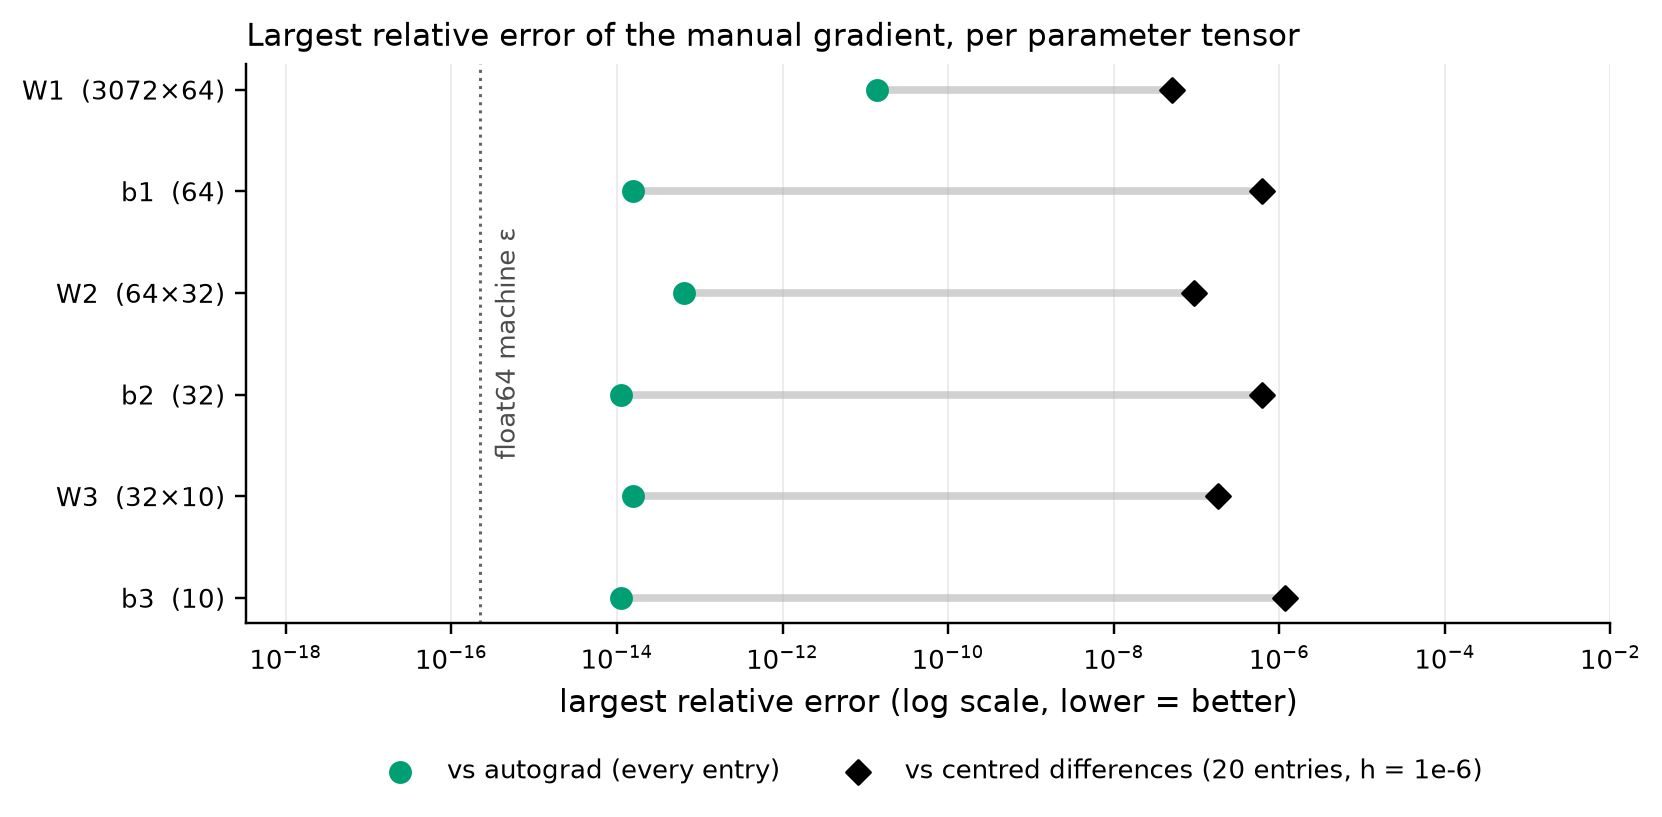

In [11]:
gc = pd.DataFrame(rows)
display(gc.style.format({"max rel. error vs autograd": "{:.1e}", "max rel. error vs FD": "{:.1e}"})
          .hide(axis="index"))
print(f"loss: manual {loss.item():.15f} | F.cross_entropy {loss_ag.item():.15f}")
print("torch.allclose(manual, autograd) for every tensor:", bool(gc["allclose vs autograd"].all()))
print("torch.allclose(manual, finite differences) for every tensor:",
      bool(gc["allclose vs FD"].all()))

# figure: largest relative error per tensor on a log axis (exact zeros drawn at the floor)
floor = 1e-18
fig, ax = plt.subplots(figsize=(8, 3.3))
ypos = np.arange(len(gc))
ag = np.maximum(gc["max rel. error vs autograd"].to_numpy(), floor)
fdv = np.maximum(gc["max rel. error vs FD"].to_numpy(), floor)
ax.hlines(ypos, np.minimum(ag, fdv), np.maximum(ag, fdv), color="0.82", lw=2.5, zorder=1)
ax.scatter(ag, ypos, color="#009E73", s=42, zorder=3, label="vs autograd (every entry)")
ax.scatter(fdv, ypos, color="black", marker="D", s=30, zorder=3,
           label=f"vs centred differences ({K} entries, h = 1e-6)")
eps64 = np.finfo(np.float64).eps
ax.axvline(eps64, color="0.4", ls=":", lw=1)
ax.text(eps64 * 1.5, (len(gc) - 1) / 2, "float64 machine ε", rotation=90, va="center",
        fontsize=8.5, color="0.3")
ax.set_xscale("log"); ax.set_xlim(floor / 3, 1e-2)
ax.set_yticks(ypos, [f"{t}  ({s})" for t, s in zip(gc["tensor"], gc["shape"])]); ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("largest relative error (log scale, lower = better)")
ax.set_title("Largest relative error of the manual gradient, per parameter tensor")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.show()

**Interpretation.** All six tensors pass both checks: `torch.allclose` is True against autograd and against centred differences, and the two losses agree to 15 decimals (3.061597340901310). Against autograd the largest relative errors are $1.1\times10^{-14}$–$1.4\times10^{-11}$, rounding-level differences from a different order of floating-point operations. That confirms $x^\top g$, $\sum g$, $gW^\top$, the ReLU mask and $(p-Y)/N$. The finite-difference errors are larger ($5.1\times10^{-8}$–$1.2\times10^{-6}$) because of the reference itself: subtracting two losses of ≈ 3.06 loses about $\varepsilon L/h\approx7\times10^{-10}$, on top of the $O(h^2)$ truncation, which is large relative to the smallest gradient entries. A real bug, such as a missing $1/N$, would give relative errors near 1.

### (c) Training the hand-written MLP with plain SGD

**How this works**
- MLP 3072‑512‑256‑10 with ReLU and Kaiming init, trained on flattened, normalised images with plain mini-batch SGD, $\theta\leftarrow\theta-\eta\,\partial L/\partial\theta$. Settings: $\eta=0.05$ constant, batch 128, 20 epochs.
- Gradients come only from the manual `backward()`. The loop runs under `torch.no_grad()`, so autograd never records anything.
- Training accuracy is measured on a fixed, clean 5k subset of the training split at the end of each epoch. The history is saved to `results/task1c_mlp.json`.

In [12]:
def train_manual_mlp(sizes=(3072, 512, 256, 10), lr=0.05, epochs=20, batch_size=128, seed=SEED):
    gen = seed_everything(seed)
    net = MLP(list(sizes))
    Xf, Xv = X_tr.flatten(1), X_va.flatten(1)
    h = {"name": "task1c_mlp", "params": net.n_params(), "lr": lr, "batch_size": batch_size,
         "device": DEVICE_NAME, "iter_loss": [], "train_loss": [], "val_loss": [], "val_acc": [],
         "train_acc": [], "epoch_time": []}

    def loss_acc(X, y):
        loss_sum, correct = 0.0, 0
        for xb, yb in batches(X, y, 1000):
            z = net.forward(xb)
            loss_sum += net.criterion.forward(z, yb).item() * len(xb)
            correct += (z.argmax(1) == yb).sum().item()
        return loss_sum / len(X), correct / len(X)

    with torch.no_grad():                                   # no autograd anywhere
        for ep in range(1, epochs + 1):
            t0, losses = time.perf_counter(), []
            for xb, yb in batches(Xf, y_tr, batch_size, shuffle=True, gen=gen):
                losses.append(net.loss(xb, yb))
                net.backward()
                net.sgd_step(lr)
            losses = torch.stack(losses).tolist()
            if AMP:
                torch.cuda.synchronize()
            h["epoch_time"].append(time.perf_counter() - t0)
            vl, va = loss_acc(Xv, y_va)
            _, ta = loss_acc(Xf[:5000], y_tr[:5000])
            h["iter_loss"] += losses
            h["train_loss"].append(float(np.mean(losses)))
            h["val_loss"].append(vl); h["val_acc"].append(va); h["train_acc"].append(ta)
            if ep == 1 or ep % 5 == 0:
                print(f"epoch {ep:>2}/{epochs} | train loss {h['train_loss'][-1]:.4f} | "
                      f"val loss {vl:.4f} | val acc {va:.2%} | {h['epoch_time'][-1]:.2f} s/epoch")
    return h

path_1c = RESULTS_DIR / "task1c_mlp.json"
if path_1c.exists() and not FORCE_RETRAIN:
    h1c = load_history("task1c_mlp"); print("[loaded]", path_1c.name)
elif RUN_TRAINING:
    h1c = train_manual_mlp()
    path_1c.write_text(json.dumps(h1c))
else:
    raise FileNotFoundError(path_1c)
best = int(np.argmax(h1c["val_acc"]))
print(f"final val acc {h1c['val_acc'][-1]:.2%} | best {h1c['val_acc'][best]:.2%} "
      f"(epoch {best + 1}) | final train-subset acc {h1c['train_acc'][-1]:.2%} | "
      f"{np.mean(h1c['epoch_time']):.2f} s/epoch")

epoch  1/20 | train loss 1.6999 | val loss 1.5981 | val acc 43.78% | 0.38 s/epoch


epoch  5/20 | train loss 1.0945 | val loss 1.5120 | val acc 48.90% | 0.37 s/epoch


epoch 10/20 | train loss 0.7361 | val loss 1.7155 | val acc 47.50% | 0.37 s/epoch


epoch 15/20 | train loss 0.4649 | val loss 1.9091 | val acc 48.80% | 0.37 s/epoch


epoch 20/20 | train loss 0.2627 | val loss 2.3339 | val acc 47.76% | 0.37 s/epoch
final val acc 47.76% | best 50.52% (epoch 7) | final train-subset acc 89.38% | 0.37 s/epoch


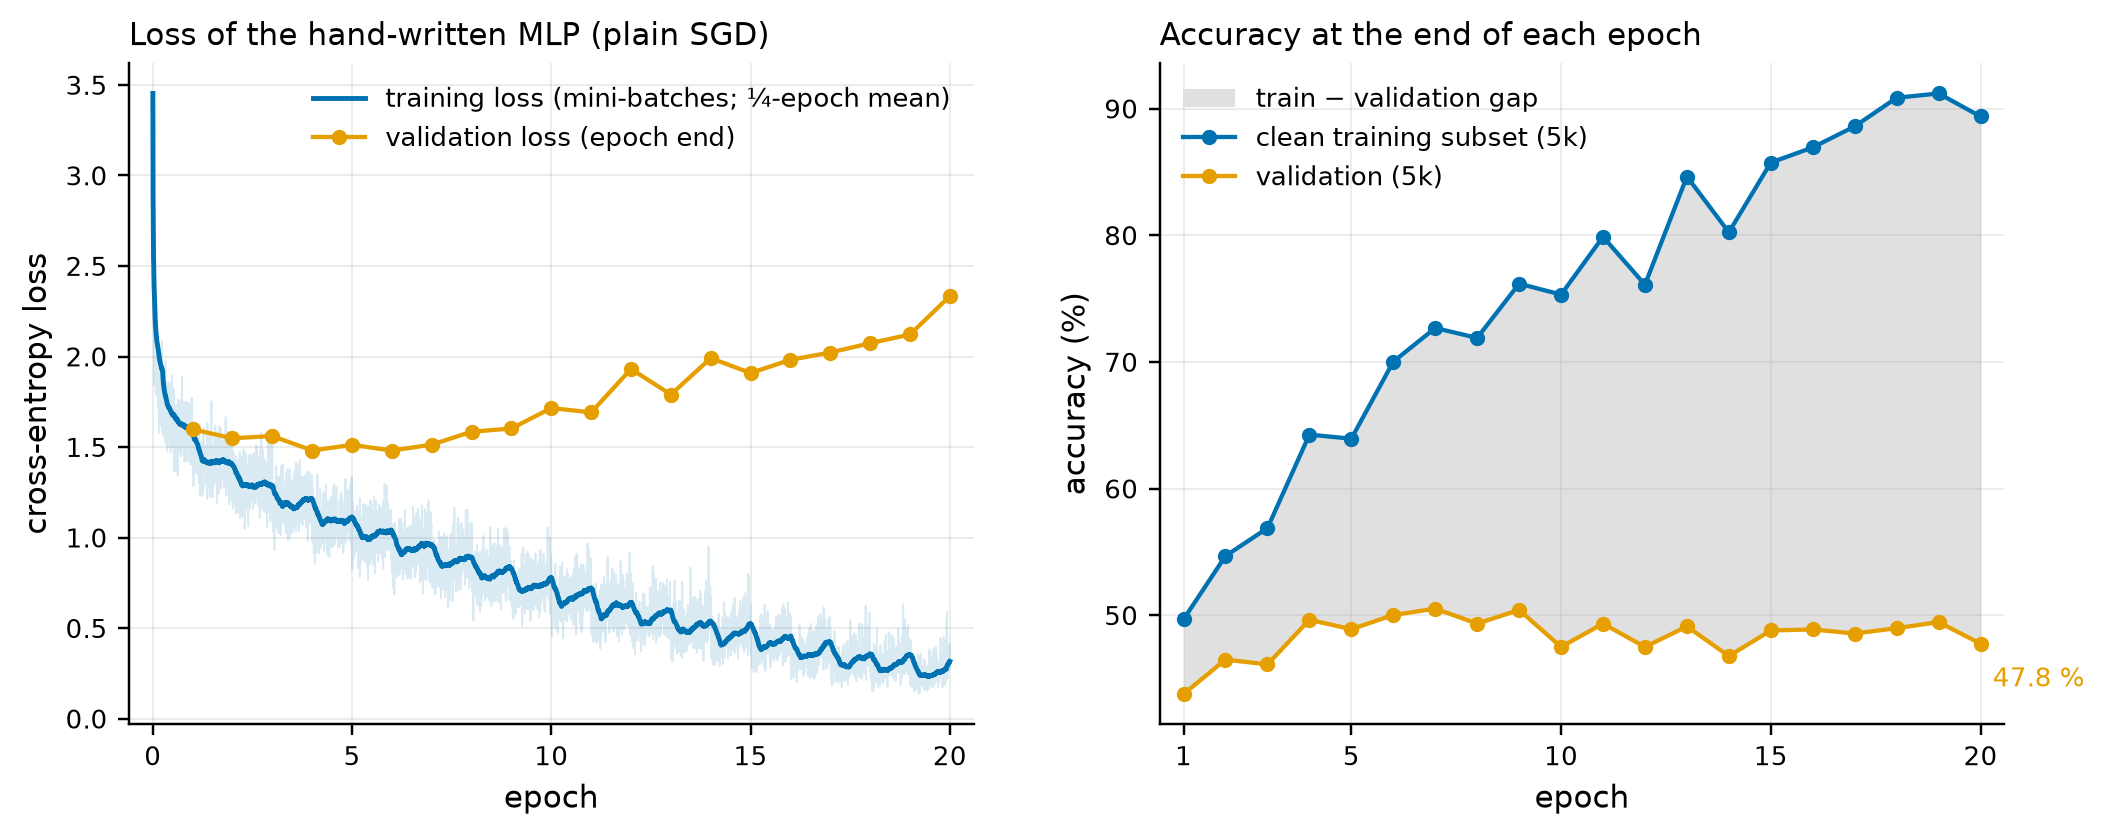

In [13]:
spe = len(h1c["iter_loss"]) // len(h1c["train_loss"])            # steps per epoch
it = np.arange(1, len(h1c["iter_loss"]) + 1) / spe
ep = np.arange(1, len(h1c["val_loss"]) + 1)
smooth = pd.Series(h1c["iter_loss"]).rolling(spe // 4, min_periods=1).mean()
tr_acc, va_acc = 100 * np.array(h1c["train_acc"]), 100 * np.array(h1c["val_acc"])

fig, (ax_l, ax_a) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"wspace": 0.22})
ax_l.plot(it, h1c["iter_loss"], color=COLORS["train"], alpha=0.15, lw=0.6)
ax_l.plot(it, smooth, color=COLORS["train"], lw=1.6,
          label="training loss (mini-batches; ¼-epoch mean)")
ax_l.plot(ep, h1c["val_loss"], "o-", color=COLORS["val"], ms=4, lw=1.4,
          label="validation loss (epoch end)")
ax_l.set(xlabel="epoch", ylabel="cross-entropy loss",
         title="Loss of the hand-written MLP (plain SGD)")
ax_l.legend(loc="upper right")

ax_a.fill_between(ep, va_acc, tr_acc, color="0.88", lw=0, label="train − validation gap")
ax_a.plot(ep, tr_acc, "o-", color=COLORS["train"], ms=4, lw=1.4, label="clean training subset (5k)")
ax_a.plot(ep, va_acc, "o-", color=COLORS["val"], ms=4, lw=1.4, label="validation (5k)")
ax_a.annotate(f"{va_acc[-1]:.1f} %", (ep[-1], va_acc[-1]), xytext=(4, -14),
              textcoords="offset points", color=COLORS["val"], fontsize=8.5)
ax_a.set(xlabel="epoch", ylabel="accuracy (%)", title="Accuracy at the end of each epoch")
ax_a.legend(loc="upper left")
ax_l.set_xticks([0, 5, 10, 15, 20]); ax_a.set_xticks([1, 5, 10, 15, 20])
for ax in (ax_l, ax_a):
    ax.margins(x=0.03)
plt.show()

**Interpretation.** The hand-written backward pass trains the network: mean training loss falls from 1.70 (epoch 1) to 0.26 (epoch 20). Validation loss bottoms out at 1.48 in epoch 6 and climbs to 2.33. Validation accuracy peaks at 50.52 % in epoch 7 and ends at 47.76 %, while clean training accuracy reaches 89.4 %: a 41.6-point gap, i.e. overfitting (L05). With 1.7 M parameters, no regularisation, and pixels treated as an unordered vector (no weight sharing, no translation invariance), the MLP memorises the 45k images, which is the motivation for CNNs. Early stopping near epoch 7 would keep the best model; Task 3 studies regularisation.

### (d) Gradient norm per layer at initialisation: sigmoid vs ReLU in a 10-layer MLP

**How this works**
- 10 linear layers (3072 → 256 ×9 → 10) with the same init scheme for both activations. Norms come from the manual backward pass on one fixed batch of 256 training images, with 5 random inits per configuration (line = median, band = min–max).
- Backward through layer $l$: $\delta_{l-1}=(\delta_l\odot f'(a_l))\,W_l^\top$ and $\partial L/\partial W_l=h_{l-1}^\top(\delta_l\odot f'(a_l))$. Each layer multiplies the signal by $f'$ and a weight matrix, so its norm changes geometrically with depth.
- Sigmoid: $\sigma'=\sigma(1-\sigma)\le0.25$. ReLU: $f'\in\{0,1\}$.
- Kaiming init, $\mathrm{std}=\sqrt{2/\text{fan\_in}}$, is designed for ReLU (the 2 makes up for the half of the units that output zero). Xavier, $\sqrt{2/(\text{fan\_in}+\text{fan\_out})}$, has half that variance on these layers and is shown for comparison.

init,activation,‖∂L/∂W₁‖ (input side),‖∂L/∂W₁₀‖ (output side),layer 1 / layer 10
kaiming,Sigmoid,1.30e-04,1.65e+00,7.89e-05
kaiming,ReLU,4.27e+00,4.24e+00,1.01e+00
xavier,Sigmoid,1.21e-05,1.55e+00,7.78e-06
xavier,ReLU,2.04e-01,4.89e-02,4.18e+00


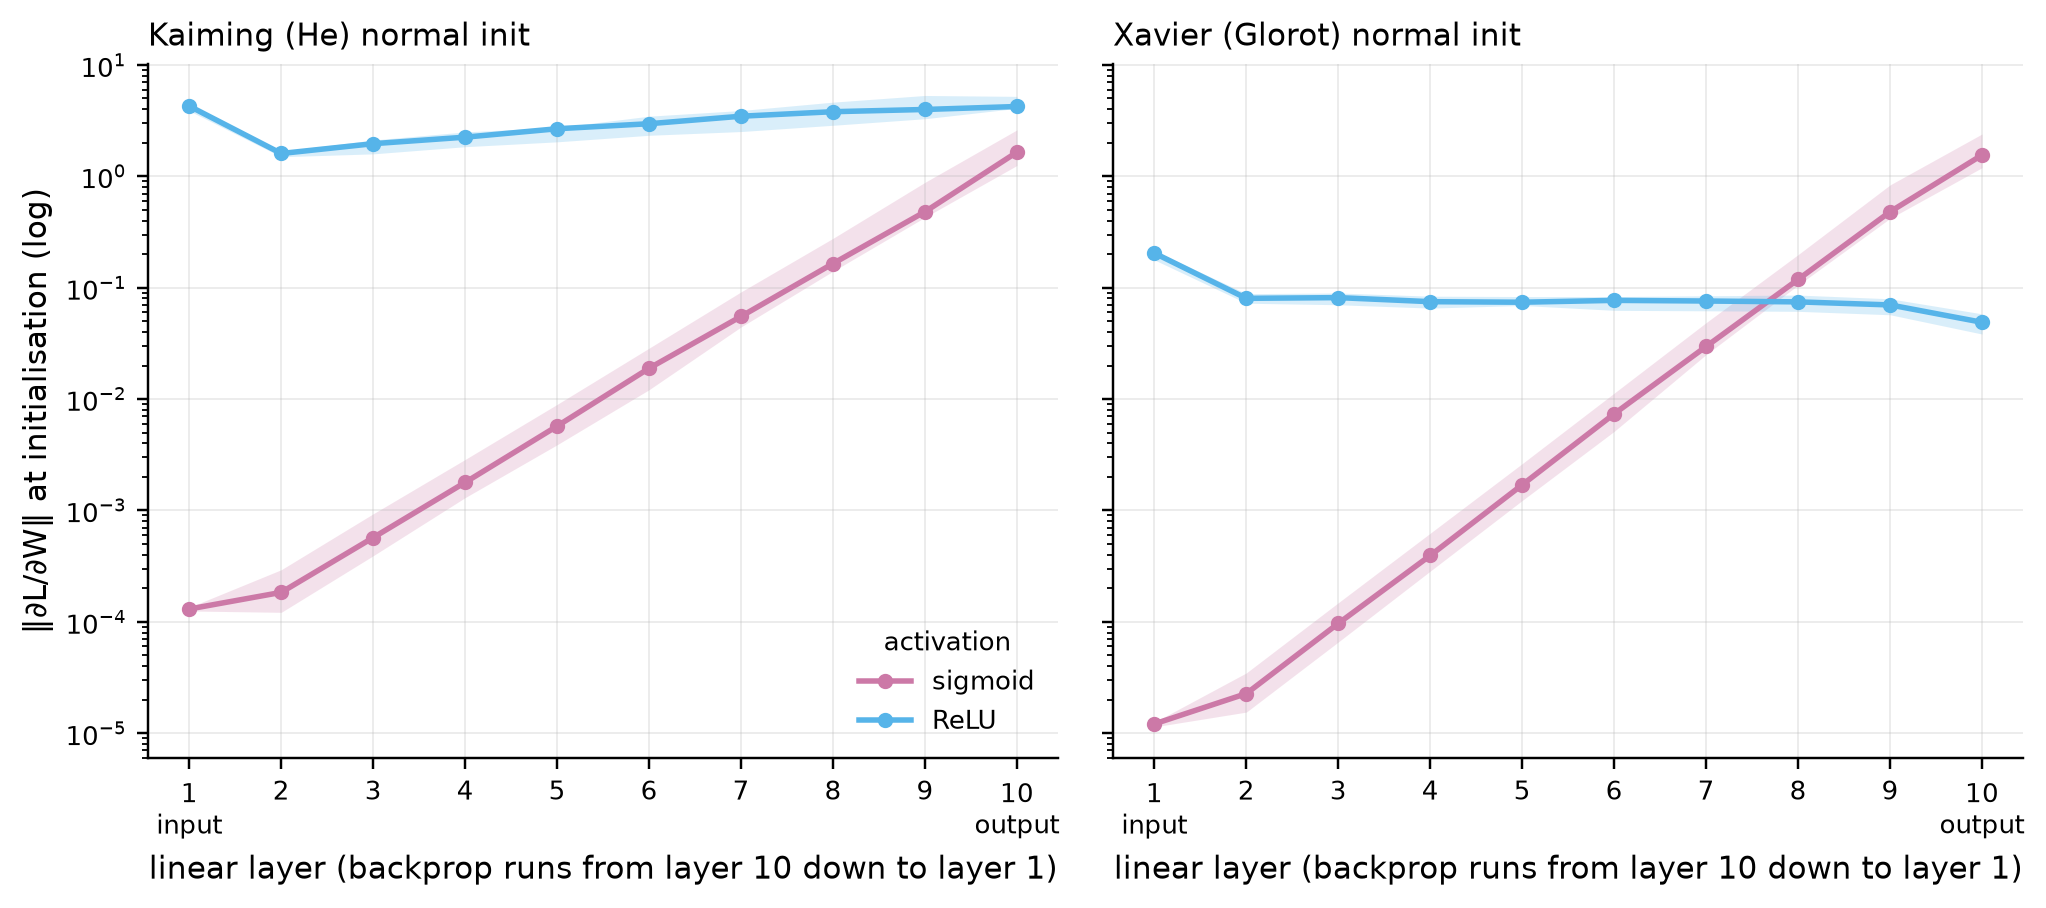

In [14]:
def layer_grad_norms(act, init, seed, x, y):
    seed_everything(seed)
    net = MLP([3072] + [256] * 9 + [10], act=act, init=init)
    net.loss(x, y)
    net.backward()
    return [lin.dW.norm().item() for lin in net.linears]      # Frobenius norm of dL/dW_l

xg, yg = X_tr[:256].flatten(1), y_tr[:256]
gn = {(init, act.__name__): np.array([layer_grad_norms(act, init, s, xg, yg) for s in range(5)])
      for init in ("kaiming", "xavier") for act in (Sigmoid, ReLU)}

summary = pd.DataFrame([{"init": init, "activation": act,
                         "‖∂L/∂W₁‖ (input side)": np.median(g[:, 0]),
                         "‖∂L/∂W₁₀‖ (output side)": np.median(g[:, -1]),
                         "layer 1 / layer 10": np.median(g[:, 0]) / np.median(g[:, -1])}
                        for (init, act), g in gn.items()])
display(summary.style.format("{:.2e}", subset=summary.columns[2:]).hide(axis="index"))

layers = np.arange(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), sharey=True, gridspec_kw={"wspace": 0.06})
titles = {"kaiming": "Kaiming (He) normal init", "xavier": "Xavier (Glorot) normal init"}
for ax, init in zip(axes, ("kaiming", "xavier")):
    for act, key in (("Sigmoid", "sigmoid"), ("ReLU", "ReLU")):
        g = gn[(init, act)]
        ax.fill_between(layers, g.min(0), g.max(0), color=COLORS[key], alpha=0.22, lw=0)
        ax.plot(layers, np.median(g, 0), "o-", color=COLORS[key], lw=1.8, ms=4, label=key)
    ax.set_yscale("log")
    ax.set_xticks(layers, ["1\ninput"] + [str(i) for i in range(2, 10)] + ["10\noutput"])
    ax.set_xlabel("linear layer (backprop runs from layer 10 down to layer 1)")
    ax.set_title(titles[init])
axes[0].set_ylabel("‖∂L/∂W‖ at initialisation (log)")
axes[0].legend(loc="lower right", title="activation", title_fontsize=8.5)
plt.show()

**Interpretation.** With the same Kaiming init, the sigmoid network's gradient norm falls from 1.65 at layer 10 to $1.3\times10^{-4}$ at layer 1 (×$7.9\times10^{-5}$, about ×0.35 per layer). The ReLU network stays at the same scale (4.24 → 4.27). This is the vanishing-gradient problem: each backward step multiplies $\delta$ by $f'(a)$ and by $W^\top$. A Kaiming 256×256 matrix scales the norm by about $\sqrt2$ and $\sigma'\le0.25$, so the sigmoid factor is about $0.25\sqrt2\approx0.35$, as measured; ReLU's derivative is 1 on active units and Kaiming's factor 2 compensates for the inactive half. Initialisation matters too: with Xavier (half the variance), sigmoid decays even faster ($7.8\times10^{-6}$, ×0.27 per layer), and ReLU gradients do not vanish (layer 1 / layer 10 = 4.2) but are 87× smaller at layer 10 (0.049 vs 4.24) because the forward activations shrink by about $\sqrt2$ per layer.

## Task 2 · Optimizers (L05)

### (a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

**How this works**
- **PyTorch momentum:** $v_t=\mu v_{t-1}+g_t$ ($v_1=g_1$), $\theta_t=\theta_{t-1}-\eta\,v_t$. The lecture form $v\leftarrow\mu v-\eta g,\ \theta\leftarrow\theta+v$ gives the same steps for a constant $\eta$; PyTorch's version applies the *current* $\eta$ to the whole buffer, which matters under a schedule. Weight decay adds $\lambda\theta$ to $g$.
- **Adam:** $m_t=\beta_1m_{t-1}+(1-\beta_1)g_t$, $v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$, $\theta_t=\theta_{t-1}-\eta\,\hat m_t/(\sqrt{\hat v_t}+\epsilon)$ with $\hat m_t=m_t/(1-\beta_1^t)$, $\hat v_t=v_t/(1-\beta_2^t)$. Bias correction undoes the pull toward the zero initial values: without it the first step would be $\approx3.2\,\eta\,\mathrm{sign}(g)$, not $\eta\,\mathrm{sign}(g)$.
- **Check:** two identical copies of the small CNN (3 × [conv 3×3 → (BN) → ReLU → max-pool], 32/64/128 channels, FC 2048 → 256 → 10), the same 30 batches, in float64 on the CPU. Every parameter is compared with `torch.allclose`, and the largest difference is printed.

In [15]:
class MySGD(torch.optim.Optimizer):
    """SGD with heavy-ball momentum (PyTorch convention) and L2 weight decay."""
    def __init__(self, params, lr, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu, wd = group["lr"], group["momentum"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad if wd == 0 else p.grad + wd * p        # L2: g <- g + lambda * theta
                if mu != 0:
                    state = self.state[p]
                    if "v" not in state:
                        state["v"] = g.clone()                   # first step: v_1 = g_1
                    else:
                        state["v"].mul_(mu).add_(g)              # v <- mu v + g
                    g = state["v"]
                p.add_(g, alpha=-lr)                             # theta <- theta - lr v
        return loss


class MyAdam(torch.optim.Optimizer):
    """Adam with bias correction (Kingma & Ba, 2015) and L2 weight decay."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group["lr"], group["betas"], group["eps"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad if wd == 0 else p.grad + wd * p
                state = self.state[p]
                if not state:
                    state["t"], state["m"], state["v"] = 0, torch.zeros_like(p), torch.zeros_like(p)
                state["t"] += 1
                t, m, v = state["t"], state["m"], state["v"]
                m.mul_(b1).add_(g, alpha=1 - b1)                 # first moment (EMA of g)
                v.mul_(b2).addcmul_(g, g, value=1 - b2)          # second moment (EMA of g^2)
                m_hat = m / (1 - b1 ** t)                        # bias correction
                v_hat = v / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)
        return loss

In [16]:
class SmallCNN(nn.Module):
    """3 x [conv3x3 -> (BN) -> ReLU -> maxpool2] (32/64/128 ch), then FC 2048 -> 256 -> 10."""
    def __init__(self, bn=False, p_drop=0.0):
        super().__init__()
        def block(c_in, c_out):
            layers = [nn.Conv2d(c_in, c_out, 3, padding=1, bias=not bn)]
            if bn:
                layers.append(nn.BatchNorm2d(c_out))
            return layers + [nn.ReLU(inplace=True), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 128))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 4 * 4, 256),
                                        nn.ReLU(inplace=True), nn.Dropout(p_drop),
                                        nn.Linear(256, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


def compare_with_torch(make_mine, make_ref, n_steps=30, batch=32, seed=SEED):
    torch.manual_seed(seed)
    base = SmallCNN().double()
    m_mine, m_ref = copy.deepcopy(base), copy.deepcopy(base)
    o_mine, o_ref = make_mine(m_mine.parameters()), make_ref(m_ref.parameters())
    Xc = X_tr[:n_steps * batch].cpu().double()
    yc = y_tr[:n_steps * batch].cpu()
    for s in range(n_steps):                                     # identical batches for both copies
        xb, yb = Xc[s * batch:(s + 1) * batch], yc[s * batch:(s + 1) * batch]
        for model, opt in ((m_mine, o_mine), (m_ref, o_ref)):
            opt.zero_grad()
            F.cross_entropy(model(xb), yb).backward()
            opt.step()
    pairs = list(zip(m_mine.parameters(), m_ref.parameters(), base.parameters()))
    return {"allclose (every parameter)": all(torch.allclose(a, b) for a, b, _ in pairs),
            "max |θ_mine − θ_torch|": max((a - b).abs().max().item() for a, b, _ in pairs),
            "max |θ_N − θ_0| (distance moved)":
                max((b - c).abs().max().item() for _, b, c in pairs)}

checks = {
    "SGD, η=0.05":                   (lambda p: MySGD(p, 0.05), lambda p: torch.optim.SGD(p, 0.05)),
    "SGD+momentum, η=0.01, μ=0.9":   (lambda p: MySGD(p, 0.01, momentum=0.9),
                                      lambda p: torch.optim.SGD(p, 0.01, momentum=0.9)),
    "SGD+momentum, + weight decay":  (
        lambda p: MySGD(p, 0.01, momentum=0.9, weight_decay=5e-4),
        lambda p: torch.optim.SGD(p, 0.01, momentum=0.9, weight_decay=5e-4)),
    "Adam, η=1e-3":                  (lambda p: MyAdam(p, 1e-3),
                                      lambda p: torch.optim.Adam(p, 1e-3)),
    "Adam, + weight decay":          (lambda p: MyAdam(p, 1e-3, weight_decay=5e-4),
                                      lambda p: torch.optim.Adam(p, 1e-3, weight_decay=5e-4)),
}
t2a = pd.DataFrame([{"optimizer": k, "steps": 30, **compare_with_torch(*v)}
                    for k, v in checks.items()])
display(t2a.style.format({"max |θ_mine − θ_torch|": "{:.1e}",
                          "max |θ_N − θ_0| (distance moved)": "{:.1e}"}).hide(axis="index"))
print("SmallCNN parameters:", f"{n_params(SmallCNN()):,} (no BN) |",
      f"{n_params(SmallCNN(bn=True)):,} (BN)")

optimizer,steps,allclose (every parameter),max |θ_mine − θ_torch|,max |θ_N − θ_0| (distance moved)
"SGD, η=0.05",30,True,0.0e+00,1.7e-02
"SGD+momentum, η=0.01, μ=0.9",30,True,0.0e+00,3.0e-02
"SGD+momentum, + weight decay",30,True,2.8e-17,3.0e-02
"Adam, η=1e-3",30,True,7.8e-15,2.6e-02
"Adam, + weight decay",30,True,2.7e-16,2.8e-02


SmallCNN parameters: 620,362 (no BN) | 620,586 (BN)


**Interpretation.** All five configurations match `torch.optim` after 30 steps (`allclose` True for every parameter). SGD with and without momentum agrees bit for bit (max $|\Delta\theta|=0$; $2.8\times10^{-17}$ with weight decay). Adam differs by at most $7.8\times10^{-15}$, which is float64 rounding: PyTorch evaluates the same update in a different order, dividing by $\sqrt{1-\beta_2^t}$ inside the denominator and folding $1/(1-\beta_1^t)$ into the step size. The check is not trivial, because the parameters moved by $1.7$–$3.0\times10^{-2}$, about $10^{12}$ times the discrepancy. This confirms PyTorch's momentum convention and Adam's bias-corrected moments.

### (b) Trajectories on $f(x,y)=\tfrac12(x^2+50y^2)$

**How this works**
- $\nabla f=(x,\,50y)$ and the Hessian is $\mathrm{diag}(1,50)$, so $\kappa=50$: one learning rate must suit a flat direction ($x$) and a steep one ($y$).
- GD multiplies $x$ by $1-\eta$ and $y$ by $1-50\eta$, and is stable only for $\eta<2/50$. So $\eta=0.035$ gives a $y$ zig-zag (factor −0.75) and an $x$ crawl (0.965 per step).
- Momentum ($\mu=0.9$, same $\eta$): both modes get complex roots of modulus $\sqrt\mu$, so every direction decays like $\mu^{t/2}$. Adam ($\eta=0.3$) scales each coordinate by its RMS gradient, so its first steps move ≈ $\eta$ in each coordinate (a 45° path).
- All three start at $(-8,1)$ and run 100 steps with my optimizers from (a). The $y$-axis is stretched.

In [17]:
def run_quadratic(make_opt, start=(-8.0, 1.0), steps=100):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = make_opt([p])
    path = [p.detach().clone()]
    for _ in range(steps):
        opt.zero_grad()
        (0.5 * (p[0] ** 2 + 50 * p[1] ** 2)).backward()
        opt.step()
        path.append(p.detach().clone())
    return torch.stack(path).numpy()

quad = lambda P: 0.5 * (P[..., 0] ** 2 + 50 * P[..., 1] ** 2)
ETA_Q, MU_Q = {"SGD": 0.035, "SGD+momentum": 0.035, "Adam": 0.3}, 0.9
paths = {"SGD": run_quadratic(lambda p: MySGD(p, ETA_Q["SGD"])),
         "SGD+momentum": run_quadratic(lambda p: MySGD(p, ETA_Q["SGD+momentum"], momentum=MU_Q)),
         "Adam": run_quadratic(lambda p: MyAdam(p, ETA_Q["Adam"]))}
for k, P in paths.items():
    f = quad(P)
    first = int(np.argmax(f < 1e-3)) if (f < 1e-3).any() else None
    print(f"{k:13s} after 100 steps (x, y) = ({P[-1, 0]:+.2e}, {P[-1, 1]:+.2e}) | "
          f"f = {f[-1]:.2e} | "
          f"first step with f < 1e-3: {first}")

SGD           after 100 steps (x, y) = (-2.27e-01, +3.21e-13) | f = 2.57e-02 | first step with f < 1e-3: None
SGD+momentum  after 100 steps (x, y) = (-3.60e-02, +4.18e-03) | f = 1.09e-03 | first step with f < 1e-3: 91
Adam          after 100 steps (x, y) = (-1.94e-02, -1.64e-03) | f = 2.56e-04 | first step with f < 1e-3: 99


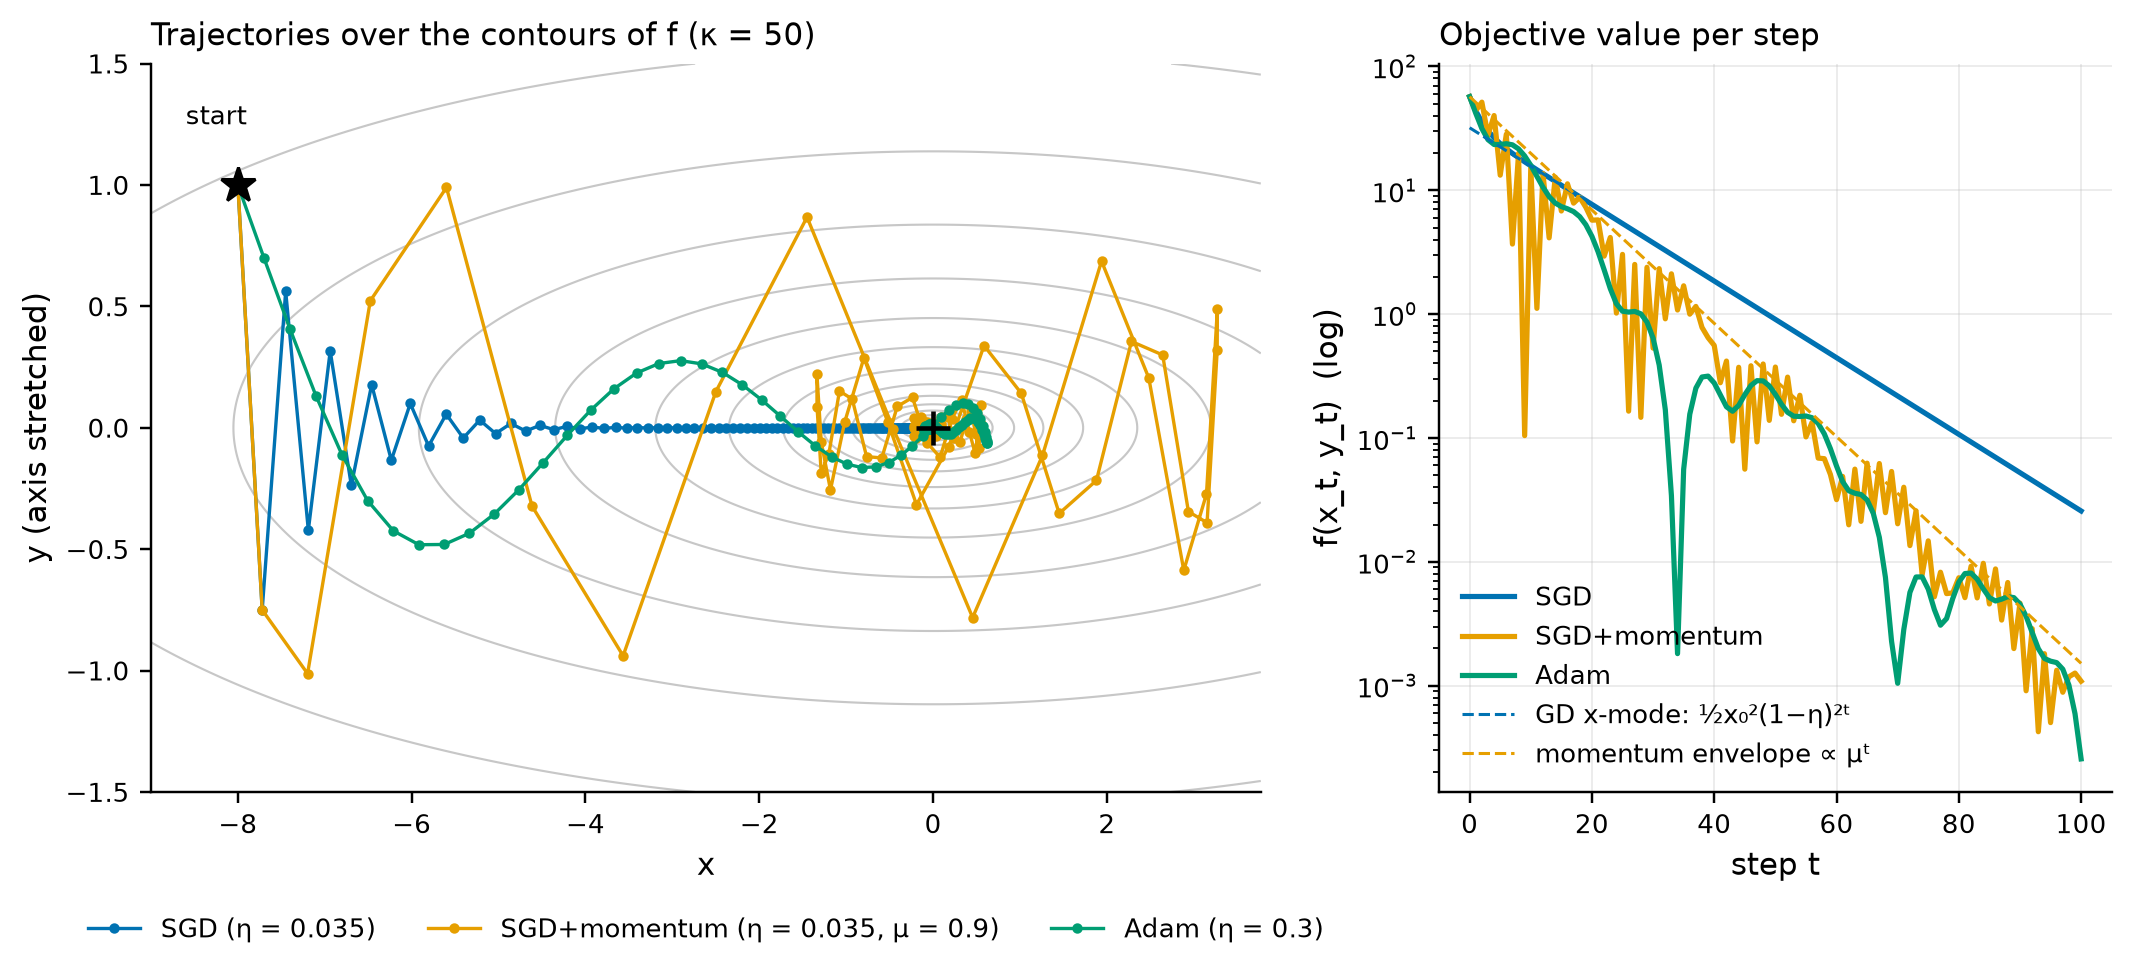

In [18]:
fig, (ax_c, ax_f) = plt.subplots(1, 2, figsize=(11.5, 4.3),
                                 gridspec_kw={"width_ratios": [1.65, 1], "wspace": 0.2})
allP = np.concatenate(list(paths.values()))
x_hi = max(3.0, allP[:, 0].max() + 0.5)                       # keep every point in view
y_hi = max(1.5, np.abs(allP[:, 1]).max() + 0.25)
XX, YY = np.meshgrid(np.linspace(-9, x_hi, 400), np.linspace(-y_hi, y_hi, 300))
ax_c.contour(XX, YY, 0.5 * (XX ** 2 + 50 * YY ** 2), levels=np.geomspace(0.02, 60, 14),
             colors="0.78", linewidths=0.7)
for k, P in paths.items():
    extra = f", μ = {MU_Q}" if k == "SGD+momentum" else ""
    ax_c.plot(P[:, 0], P[:, 1], "-o", color=COLORS[k], ms=2.4, lw=1.1,
              label=f"{k} (η = {ETA_Q[k]}{extra})")
ax_c.plot(-8, 1, marker="*", color="black", ms=12, zorder=5)
ax_c.annotate("start", (-8, 1), xytext=(-8.6, 1.25), fontsize=8.5)
ax_c.plot(0, 0, marker="+", color="black", ms=11, mew=1.5, zorder=5)
ax_c.set(xlabel="x", ylabel="y (axis stretched)", xlim=(-9, x_hi), ylim=(-y_hi, y_hi),
         title="Trajectories over the contours of f (κ = 50)")
ax_c.grid(False)
ax_c.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)

t = np.arange(len(paths["SGD"]))
for k, P in paths.items():
    ax_f.semilogy(t, quad(P), color=COLORS[k], lw=1.7, label=k)
ax_f.semilogy(t, 0.5 * 8 ** 2 * (1 - ETA_Q["SGD"]) ** (2 * t), "--", color=COLORS["SGD"], lw=1,
              label="GD x-mode: ½x₀²(1−η)²ᵗ")
ax_f.semilogy(t, quad(paths["SGD"][0]) * MU_Q ** t, "--", color=COLORS["SGD+momentum"], lw=1,
              label="momentum envelope ∝ μᵗ")
ax_f.set(xlabel="step t", ylabel="f(x_t, y_t)  (log)", title="Objective value per step")
ax_f.legend(loc="lower left")
plt.show()

**Interpretation.** SGD shows both effects of $\kappa=50$. In $y$ the factor $1-50\eta=-0.75$ causes the zig-zag. In $x$ the factor 0.965 leaves it at $x=-0.227$ after 100 steps, exactly on the dashed $\tfrac12x_0^2(1-\eta)^{2t}$ line ($f=2.6\times10^{-2}$). Momentum with the same $\eta$ builds velocity along the consistent $x$-gradient and follows the $\mu^t$ envelope, first reaching $f<10^{-3}$ at step 91. Its price is overshoot: both modes decay only at $\sqrt\mu\approx0.95$ per step, so it swings past the minimum to $x>3$. Adam's first step is exactly $(+0.3,-0.3)=-\eta\,\mathrm{sign}(\nabla f)$: per-coordinate scaling removes the 50× curvature difference, so it heads diagonally and ends with the lowest $f$ ($2.6\times10^{-4}$).

### (c) Learning-rate sensitivity of the small CNN

**How this works**
- The small CNN has **no batch norm** here, so the learning rate's effect isn't damped. Batch norm is added in Task 3(a).
- 15 epochs, batch 128, constant learning rate, no augmentation and no weight decay, using my optimizers from (a). Only the optimizer and $\eta$ change between runs, and the seed gives every run the same initial weights and batch order.
- Three log-spaced (×10) rates per optimizer. The SGD+momentum grid is 10× lower than plain SGD because its effective step is $\eta/(1-\mu)=10\eta$. A run whose loss turns inf/NaN is stopped and marked *diverged*.
- The left plot shows the final-epoch validation accuracy (filled markers) and the best epoch (hollow markers). The right plot shows the training loss at each optimizer's best rate, with the other rates faint.

In [19]:
LR_GRID = {"SGD": [0.01, 0.1, 1.0], "SGD+momentum": [0.001, 0.01, 0.1], "Adam": [1e-4, 1e-3, 1e-2]}
MAKE_OPT = {"SGD": lambda lr: (lambda ps: MySGD(ps, lr)),
            "SGD+momentum": lambda lr: (lambda ps: MySGD(ps, lr, momentum=0.9)),
            "Adam": lambda lr: (lambda ps: MyAdam(ps, lr))}
EPOCHS_2C = 15
h2c = {}
for opt_name, lrs in LR_GRID.items():
    for lr in lrs:
        name = f"task2c_{opt_name.replace('+', '_')}_lr{lr:g}"
        h2c[(opt_name, lr)] = run_experiment(name, SmallCNN, MAKE_OPT[opt_name](lr), EPOCHS_2C,
                                             log_every=5)

task2c_SGD_lr0.01 | epoch   1/15 | train loss 2.2583 | val loss 2.1599 | val acc 24.86% | 2.9 s/epoch


task2c_SGD_lr0.01 | epoch   5/15 | train loss 1.5085 | val loss 1.5135 | val acc 45.38% | 2.5 s/epoch


task2c_SGD_lr0.01 | epoch  10/15 | train loss 1.2287 | val loss 1.3376 | val acc 52.18% | 2.5 s/epoch


task2c_SGD_lr0.01 | epoch  15/15 | train loss 1.0337 | val loss 1.1195 | val acc 61.08% | 2.5 s/epoch


task2c_SGD_lr0.1 | epoch   1/15 | train loss 1.8269 | val loss 1.5635 | val acc 44.66% | 2.5 s/epoch


...

task2c_Adam_lr0.001 | epoch  15/15 | train loss 0.0850 | val loss 1.3104 | val acc 74.80% | 2.9 s/epoch


task2c_Adam_lr0.01 | epoch   1/15 | train loss 2.0024 | val loss 1.5836 | val acc 42.08% | 2.9 s/epoch


task2c_Adam_lr0.01 | epoch   5/15 | train loss 1.4075 | val loss 1.4912 | val acc 46.46% | 2.9 s/epoch


task2c_Adam_lr0.01 | epoch  10/15 | train loss 1.3336 | val loss 1.4575 | val acc 48.20% | 3.0 s/epoch


task2c_Adam_lr0.01 | epoch  15/15 | train loss 1.2955 | val loss 1.4997 | val acc 47.38% | 2.9 s/epoch


optimizer,η,final val acc (%),best val acc (%),best epoch,final train loss,epochs run,status
SGD,0.01,61.08,61.08,15,1.0337,15,ok
SGD,0.1,69.92,73.82,12,0.1197,15,ok
SGD,1,9.64,9.64,1,nan,1,diverged
SGD+momentum,0.001,63.30,63.30,15,1.0056,15,ok
SGD+momentum,0.01,74.90,76.16,13,0.0906,15,ok
SGD+momentum,0.1,46.24,62.56,5,1.3822,15,ok
Adam,0.0001,68.66,68.66,15,0.8386,15,ok
Adam,0.001,74.80,75.76,8,0.0850,15,ok
Adam,0.01,47.38,49.04,8,1.2955,15,ok


best η per optimizer (final val acc): {'Adam': np.float64(0.001), 'SGD': np.float64(0.1), 'SGD+momentum': np.float64(0.01)}


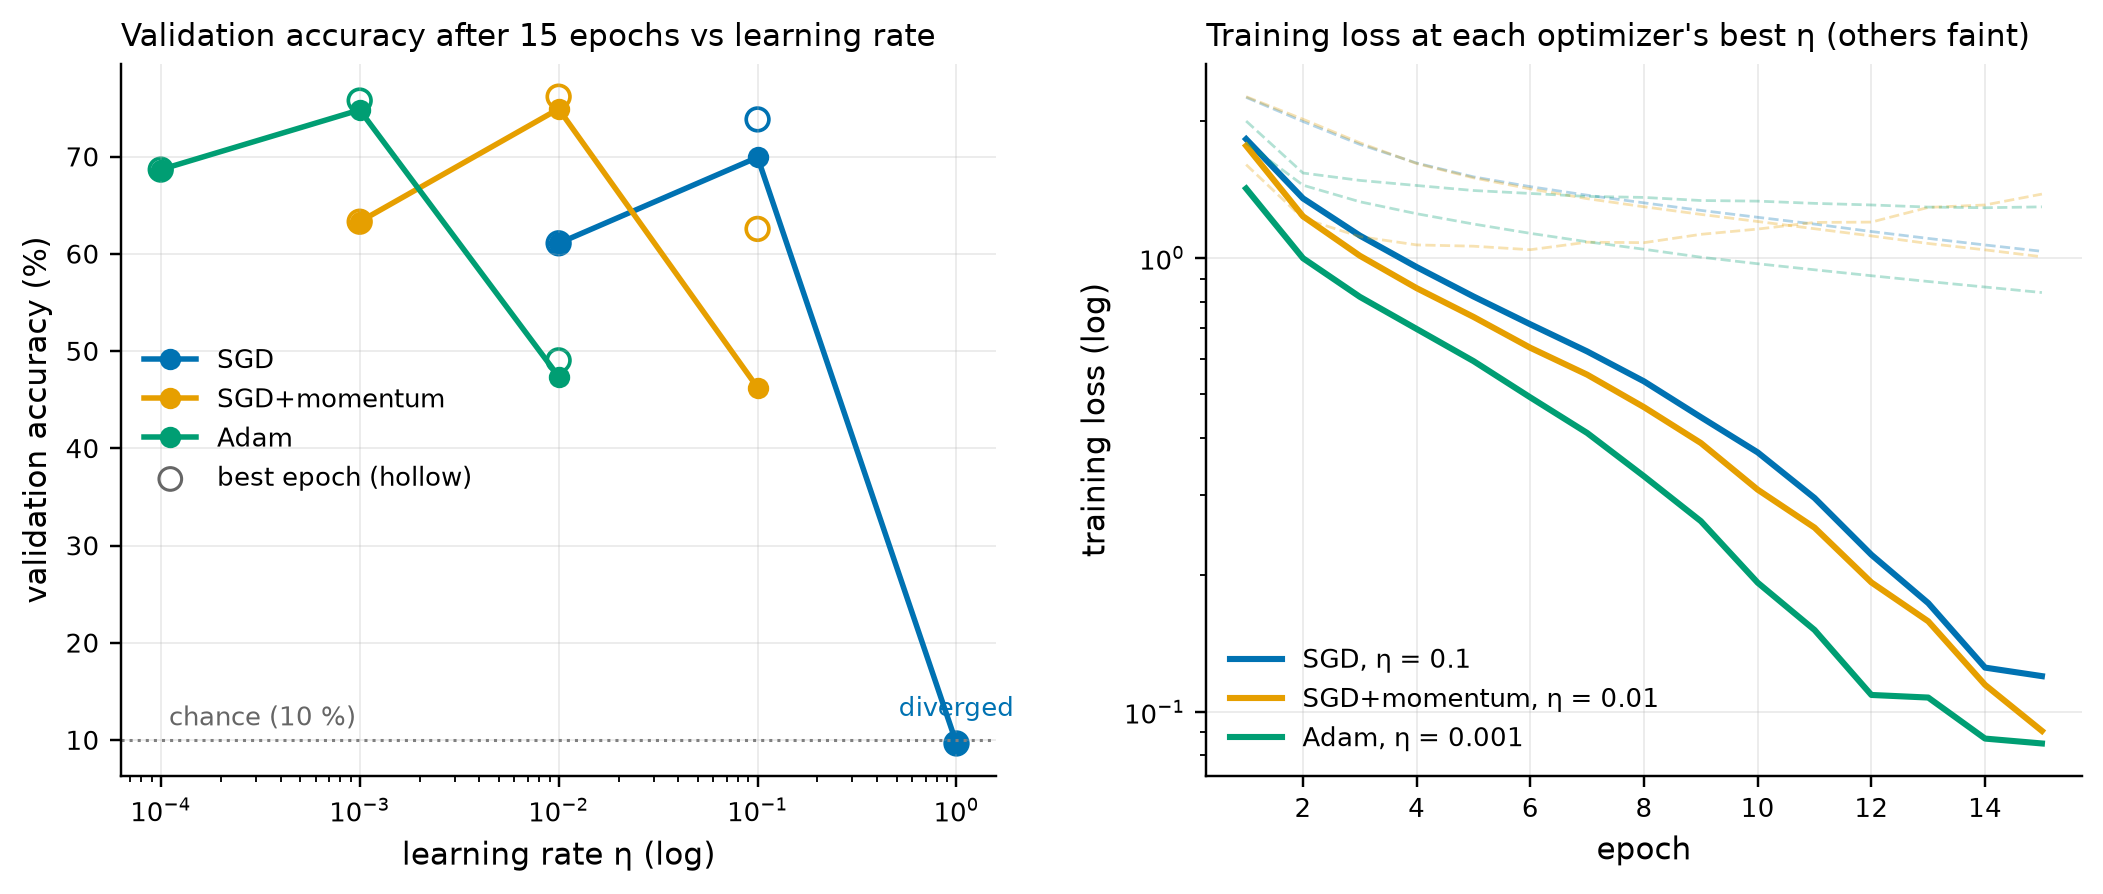

In [20]:
rows = []
for (opt_name, lr), h in h2c.items():
    va = 100 * np.array(h["val_acc"])
    rows.append({"optimizer": opt_name, "η": lr, "final val acc (%)": va[-1],
                 "best val acc (%)": np.nanmax(va), "best epoch": int(np.nanargmax(va)) + 1,
                 "final train loss": h["train_loss"][-1], "epochs run": len(va),
                 "status": "diverged" if h["diverged"] else "ok"})
t2c = pd.DataFrame(rows)
display(t2c.style.format({"η": "{:g}", "final val acc (%)": "{:.2f}", "best val acc (%)": "{:.2f}",
                          "final train loss": "{:.4f}"}).hide(axis="index"))
best_lr = {o: d.loc[d["final val acc (%)"].idxmax(), "η"] for o, d in t2c.groupby("optimizer")}
print("best η per optimizer (final val acc):", best_lr)

fig, (ax_a, ax_l) = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"wspace": 0.24})
for o in LR_GRID:
    d = t2c[t2c.optimizer == o]
    ax_a.plot(d["η"], d["final val acc (%)"], "-o", color=COLORS[o], lw=1.8, ms=6, label=o)
    ax_a.scatter(d["η"], d["best val acc (%)"], facecolors="none", edgecolors=COLORS[o],
                 s=55, lw=1.2)
    for _, r in d[d.status == "diverged"].iterrows():
        ax_a.annotate("diverged", (r["η"], r["final val acc (%)"]), xytext=(0, 9),
                      textcoords="offset points", ha="center", fontsize=8.5, color=COLORS[o])
ax_a.scatter([], [], facecolors="none", edgecolors="0.4", s=55, label="best epoch (hollow)")
ax_a.axhline(10, color="0.5", ls=":", lw=1)
ax_a.text(1.1e-4, 11.5, "chance (10 %)", fontsize=8.5, color="0.4")
ax_a.set_xscale("log")
ax_a.set(xlabel="learning rate η (log)", ylabel="validation accuracy (%)",
         title="Validation accuracy after 15 epochs vs learning rate")
ax_a.legend(loc="center left")

ep = np.arange(1, EPOCHS_2C + 1)
for o, lrs in LR_GRID.items():
    for lr in lrs:
        tl = h2c[(o, lr)]["train_loss"]
        is_best = lr == best_lr[o]
        ax_l.plot(ep[:len(tl)], tl, color=COLORS[o], lw=2 if is_best else 0.9,
                  alpha=1 if is_best else 0.3, ls="-" if is_best else "--",
                  label=f"{o}, η = {lr:g}" if is_best else None)
ax_l.set_yscale("log")
ax_l.set(xlabel="epoch", ylabel="training loss (log)",
         title="Training loss at each optimizer's best η (others faint)")
ax_l.legend(loc="lower left")
plt.show()

**Interpretation.** Each optimizer has a narrow good range: the best final accuracies are 69.92 % (SGD, $\eta=0.1$), 74.90 % (SGD+momentum, $\eta=0.01$) and 74.80 % (Adam, $\eta=10^{-3}$). One decade away costs 6–29 points, or divergence: SGD at $\eta=1$ reached a NaN loss in the first epoch (this network has no batch norm). Too small a rate under-trains (61.08 %, 63.30 %, 68.66 %, all still improving at epoch 15); too large a rate stalls (Adam at $10^{-2}$) or degrades (momentum at 0.1, training loss 1.06 → 1.38). SGD at 0.1 and momentum at 0.01 follow almost the same loss curve, as expected from the equal effective step $\eta/(1-\mu)=0.1$. Adam is the least sensitive at the low end because its per-parameter normalisation sets the step size in parameter units.

## Task 3 · Regularisation and residual connections (L05, L08)

### (a) Regularising a small CNN with batch norm trained on 5k images

**How this works**
- A seeded 5k subset of the training split overfits quickly, which makes regularisation effects visible. All configurations share SmallCNN with BN, SGD (momentum 0.9, $\eta=0.05$, cosine to 0), batch 128, 60 epochs and seeds 0, 1, 2 (mean ± std).
- **Weight decay** ($\lambda=5\times10^{-4}$) adds $\lambda\theta$ to the gradient. **Dropout** ($p=0.5$, hidden FC layer) zeroes units in training and scales survivors by $1/(1-p)$.
- **Flip + crop:** random horizontal flip, random 32×32 crop of the 4-pixel zero-padded image. **Cutout:** one 16×16 square set to 0 (the mean pixel). **Mixup:** $\tilde x=\lambda x_i+(1-\lambda)x_j$, loss $\lambda\,\mathrm{CE}(y_i)+(1-\lambda)\,\mathrm{CE}(y_j)$, $\lambda\sim\mathrm{Beta}(1,1)$.
- **Train accuracy** is measured on the *clean* 5k training images (eval mode) after every epoch, so it stays comparable to validation accuracy under augmentation or mixup.

In [21]:
def flip_crop(x, pad=4, p_flip=0.5):
    """Random horizontal flip (prob. p_flip) + random 32x32 crop of the zero-padded batch."""
    n, dev = x.size(0), x.device
    x = torch.where(torch.rand(n, 1, 1, 1, device=dev) < p_flip, x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))                    # 0 = mean pixel after normalisation
    i = torch.randint(0, 2 * pad + 1, (n, 1, 1, 1), device=dev)    # top-left corner of each crop
    j = torch.randint(0, 2 * pad + 1, (n, 1, 1, 1), device=dev)
    ar = torch.arange(32, device=dev)
    rows, cols = i + ar.view(1, 1, 32, 1), j + ar.view(1, 1, 1, 32)
    img = torch.arange(n, device=dev).view(n, 1, 1, 1)
    chan = torch.arange(3, device=dev).view(1, 3, 1, 1)
    return xp[img, chan, rows, cols]                       # advanced indexing -> (n, 3, 32, 32)

def cutout(x, size=16):
    """Zero one size x size square per image (DeVries & Taylor, 2017)."""
    n, _, h, w = x.shape
    cy = torch.randint(0, h, (n, 1, 1), device=x.device)
    cx = torch.randint(0, w, (n, 1, 1), device=x.device)
    ys = torch.arange(h, device=x.device).view(1, h, 1)
    xs = torch.arange(w, device=x.device).view(1, 1, w)
    half = size // 2                                       # rows/cols in [c - 8, c + 8) are cut
    hole = (ys >= cy - half) & (ys < cy + half) & (xs >= cx - half) & (xs < cx + half)
    return x * (~hole).unsqueeze(1)

def mixup(x, y, alpha=1.0):
    """Mix each image with a shuffled partner; returns both label sets and lambda."""
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[perm], y, y[perm], lam

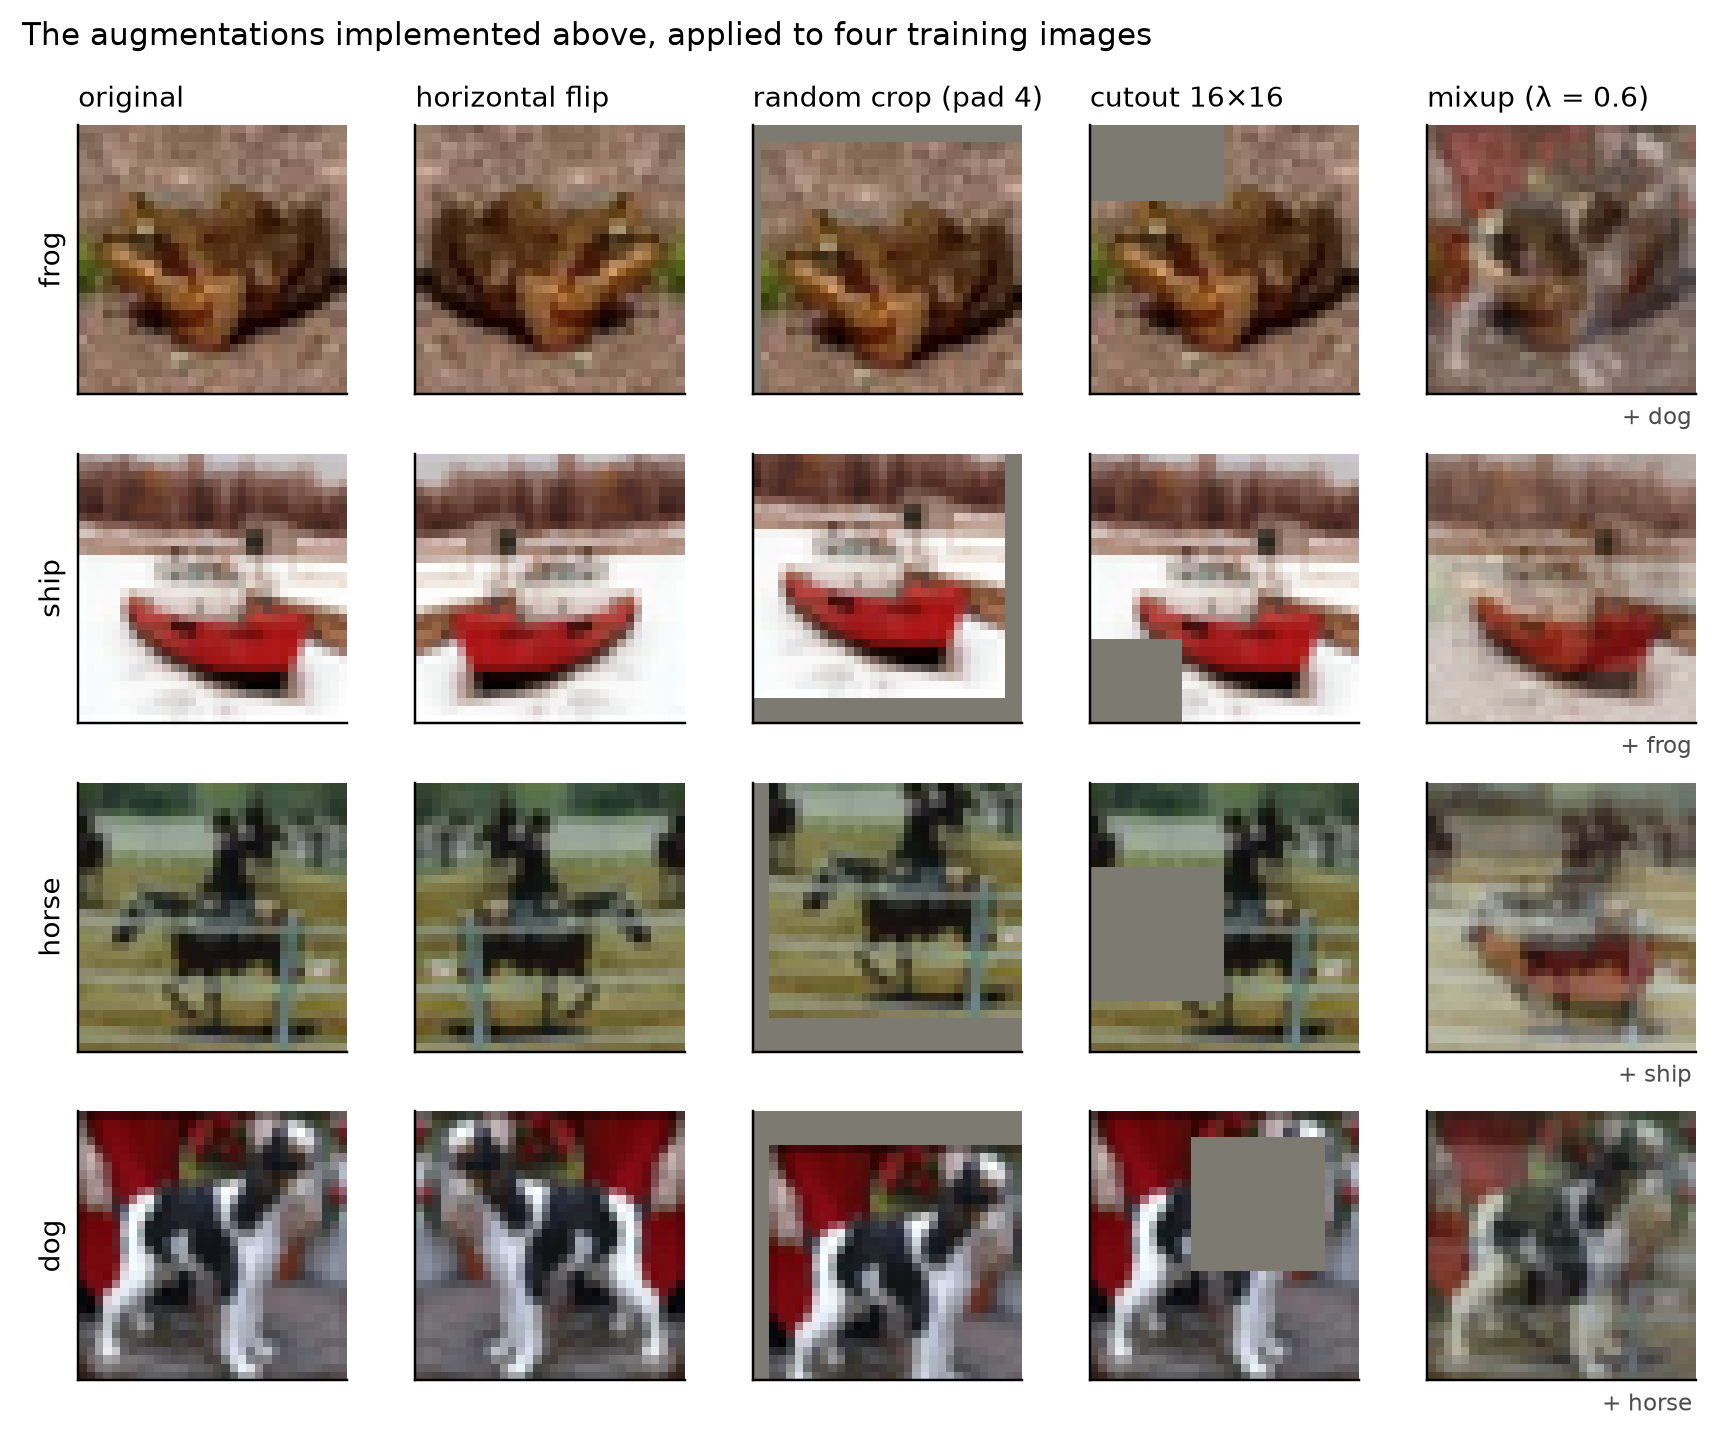

In [22]:
# what the network sees: 4 training images, each augmentation applied once (fixed seed)
seed_everything(1)
x4, y4 = X_tr[:4], y_tr[:4]
lam_show = 0.6                                     # fixed λ and partner, for display only
xm, ym2 = lam_show * x4 + (1 - lam_show) * x4.roll(1, dims=0), y4.roll(1, dims=0)
views = {"original": x4, "horizontal flip": x4.flip(3),
         "random crop (pad 4)": flip_crop(x4, p_flip=0.0), "cutout 16×16": cutout(x4),
         f"mixup (λ = {lam_show})": xm}
show = lambda t: (t * STD.view(3, 1, 1).to(t.device) + MEAN.view(3, 1, 1).to(t.device)).clamp(0, 1)
fig, axes = plt.subplots(4, 5, figsize=(8, 6.6))
for c, (title, v) in enumerate(views.items()):
    for r in range(4):
        ax = axes[r, c]
        ax.imshow(show(v[r]).permute(1, 2, 0).cpu().numpy())
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if r == 0:
            ax.set_title(title, fontsize=9)
        if c == 0:
            ax.set_ylabel(CLASSES[y4[r]], fontsize=9)
        if c == 4:
            ax.text(31, 33, f"+ {CLASSES[ym2[r]]}", ha="right", va="top", fontsize=7.5, color="0.3")
fig.suptitle("The augmentations implemented above, applied to four training images",
             x=0.02, ha="left", fontsize=10)
plt.tight_layout()
plt.show()

**Interpretation.** Each transform does what its definition says. The flip mirrors the scene. The crop shifts the image by up to 4 pixels and fills the border with the grey mean pixel (0 after normalisation). Cutout hides a 16×16 square, which the border clips for frog and ship. Mixup blends two images 0.6 / 0.4, and the loss mixes their labels in the same ratio. Flips, shifts and occlusions keep the class, so they create new label-preserving training images, whereas mixup creates images between classes and asks for correspondingly mixed predictions.

In [23]:
sub = torch.randperm(len(X_tr), generator=torch.Generator().manual_seed(SEED))[:5000].to(DEVICE)
X_sub, y_sub = X_tr[sub], y_tr[sub]
print("5k training subset, images per class:", torch.bincount(y_sub, minlength=10).tolist())

EPOCHS_3A, SEEDS_3A = 60, (0, 1, 2)
COSINE = lambda opt, total_steps: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total_steps)
REG_CONFIGS = {
    "baseline":     {},
    "weight decay": {"wd": 5e-4},
    "dropout":      {"p_drop": 0.5},
    "flip+crop":    {"augment": flip_crop},
    "cutout":       {"augment": cutout},
    "mixup":        {"mix_fn": mixup},
    "all combined": {"wd": 5e-4, "p_drop": 0.5, "augment": lambda x: cutout(flip_crop(x)),
                     "mix_fn": mixup},
}
COLORS.update({"baseline": "#555555", "weight decay": "#0072B2", "dropout": "#56B4E9",
               "flip+crop": "#009E73", "cutout": "#E69F00", "mixup": "#CC79A7",
               "all combined": "#D55E00"})

def run_reg(cfg_name, seed):
    cfg = REG_CONFIGS[cfg_name]
    return run_experiment(f"task3a_{cfg_name.replace(' ', '_').replace('+', '_')}_s{seed}",
                          lambda: SmallCNN(bn=True, p_drop=cfg.get("p_drop", 0.0)),
                          lambda ps: torch.optim.SGD(ps, lr=0.05, momentum=0.9,
                                                     weight_decay=cfg.get("wd", 0.0)),
                          EPOCHS_3A, X=X_sub, y=y_sub, make_sched=COSINE,
                          augment=cfg.get("augment"), mix_fn=cfg.get("mix_fn"),
                          eval_train=(X_sub, y_sub), seed=seed)

h3a = {}
for cfg_name in REG_CONFIGS:
    with contextlib.redirect_stdout(io.StringIO()):         # one summary line per config instead
        runs = [run_reg(cfg_name, s) for s in SEEDS_3A]
    h3a[cfg_name] = runs
    tr = [100 * r["train_acc"][-1] for r in runs]
    va = [100 * r["val_acc"][-1] for r in runs]
    print(f"{cfg_name:13s} | clean train acc {np.mean(tr):6.2f} % | val acc {np.mean(va):5.2f} ± "
          f"{np.std(va):.2f} % | {np.mean([np.mean(r['epoch_time']) for r in runs]):.2f} s/epoch")

5k training subset, images per class: [493, 510, 507, 485, 472, 514, 506, 509, 529, 475]


baseline      | clean train acc  99.98 % | val acc 64.23 ± 0.17 % | 0.29 s/epoch


weight decay  | clean train acc  99.99 % | val acc 65.20 ± 0.09 % | 0.30 s/epoch


dropout       | clean train acc  99.37 % | val acc 65.63 ± 0.32 % | 0.24 s/epoch


flip+crop     | clean train acc  92.10 % | val acc 71.79 ± 0.34 % | 0.28 s/epoch


cutout        | clean train acc  99.93 % | val acc 66.35 ± 0.17 % | 0.29 s/epoch


mixup         | clean train acc  99.89 % | val acc 63.97 ± 0.44 % | 0.31 s/epoch


all combined  | clean train acc  62.73 % | val acc 58.22 ± 1.13 % | 0.37 s/epoch


configuration,train acc (%),val acc (%),gap (pts),Δ val vs baseline (pts)
baseline,99.98 ± 0.02,64.23 ± 0.17,35.75,+0.00
weight decay,99.99 ± 0.02,65.20 ± 0.09,34.79,+0.97
dropout,99.37 ± 0.20,65.63 ± 0.32,33.74,+1.40
flip+crop,92.10 ± 0.36,71.79 ± 0.34,20.31,+7.57
cutout,99.93 ± 0.01,66.35 ± 0.17,33.58,+2.13
mixup,99.89 ± 0.02,63.97 ± 0.44,35.92,-0.25
all combined,62.73 ± 1.34,58.22 ± 1.13,4.51,-6.01


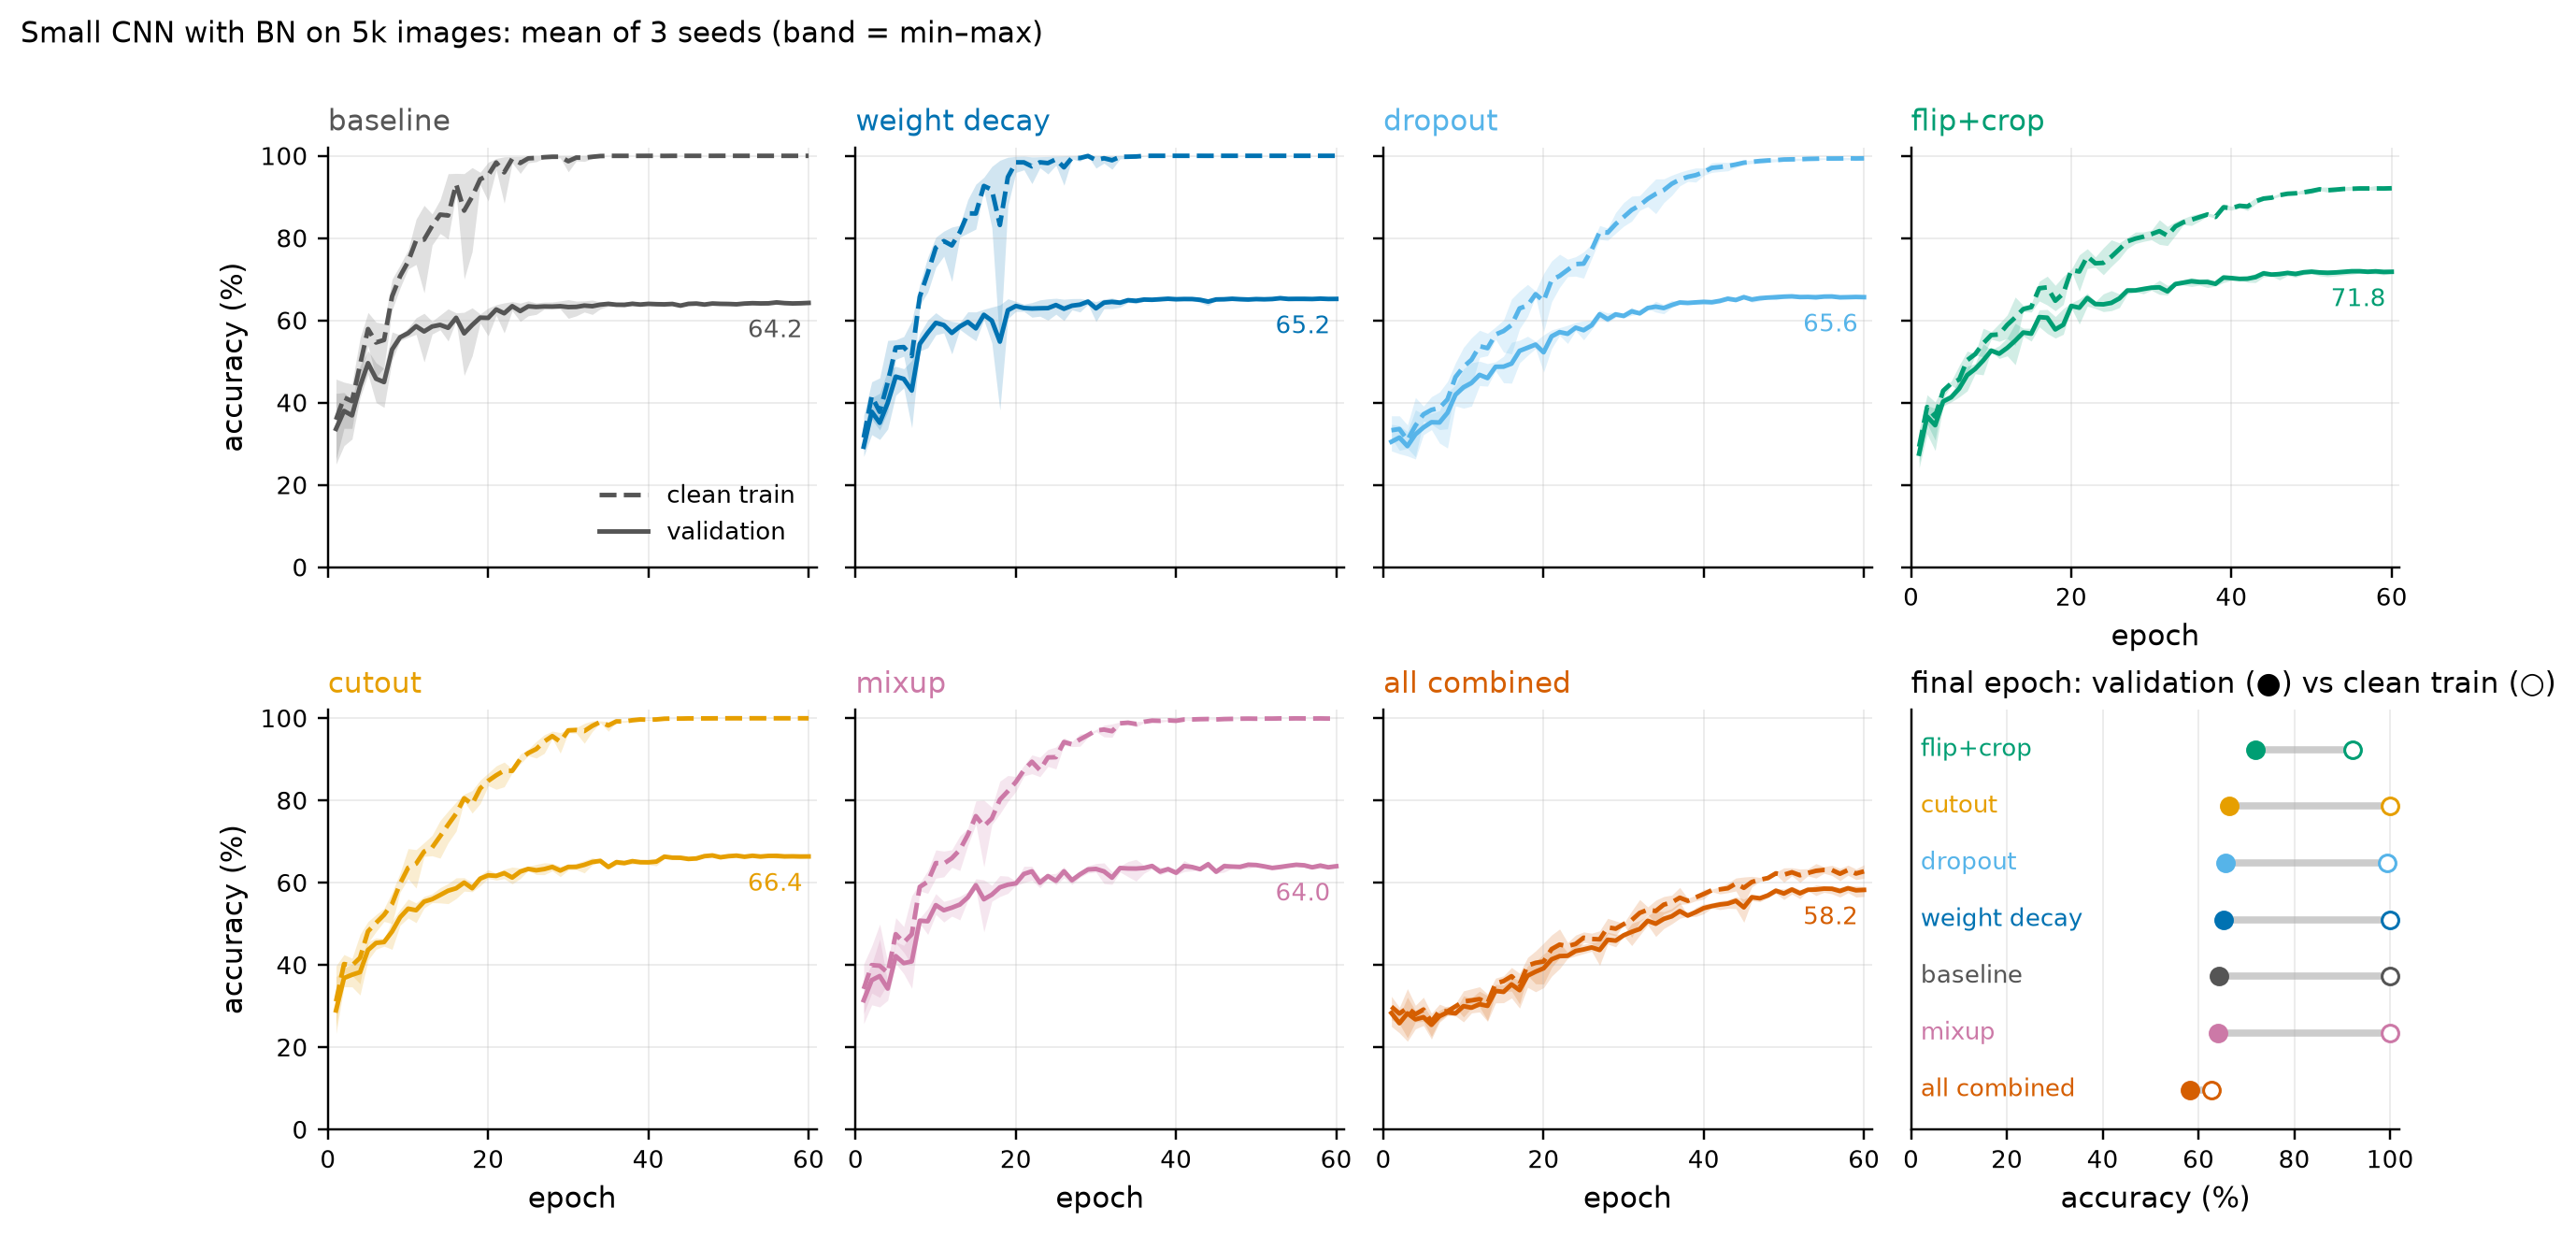

In [24]:
rows = []
for cfg_name, runs in h3a.items():
    tr = np.array([100 * r["train_acc"][-1] for r in runs])
    va = np.array([100 * r["val_acc"][-1] for r in runs])
    rows.append({"configuration": cfg_name, "train acc (%)": f"{tr.mean():.2f} ± {tr.std():.2f}",
                 "val acc (%)": f"{va.mean():.2f} ± {va.std():.2f}", "gap (pts)": (tr - va).mean(),
                 "Δ val vs baseline (pts)": np.nan, "_va": va.mean()})
t3a = pd.DataFrame(rows)
t3a["Δ val vs baseline (pts)"] = t3a["_va"] - t3a.loc[t3a.configuration == "baseline", "_va"].item()
fmt = {"gap (pts)": "{:.2f}", "Δ val vs baseline (pts)": "{:+.2f}"}
display(t3a.drop(columns="_va").style.format(fmt).hide(axis="index"))

ep = np.arange(1, EPOCHS_3A + 1)
fig, axes = plt.subplots(2, 4, figsize=(13, 6.2), gridspec_kw={"hspace": 0.34, "wspace": 0.08})
for ax, (cfg_name, runs) in zip(axes.flat, h3a.items()):
    col = COLORS[cfg_name]
    for key, ls, lab in (("train_acc", "--", "clean train"), ("val_acc", "-", "validation")):
        A = 100 * np.array([r[key] for r in runs])
        ax.fill_between(ep, A.min(0), A.max(0), color=col, alpha=0.18, lw=0)
        ax.plot(ep, A.mean(0), ls, color=col, lw=1.6, label=lab)
    va_end = 100 * np.mean([r["val_acc"][-1] for r in runs])
    ax.annotate(f"{va_end:.1f}", (EPOCHS_3A, va_end), xytext=(-2, -12), textcoords="offset points",
                ha="right", fontsize=8.5, color=col)
    ax.set_title(cfg_name, color=col)
    ax.set(xlim=(0, EPOCHS_3A + 1), ylim=(0, 102))
for k, ax in enumerate(axes.flat[:7]):        # shared-axis look; the 8th panel keeps its own axes
    if k % 4:
        ax.set_yticklabels([])
    if k < 3:
        ax.set_xticklabels([])
    else:
        ax.set_xlabel("epoch")
axes[0, 0].legend(loc="lower right")
for ax in axes[:, 0]:
    ax.set_ylabel("accuracy (%)")

# 8th panel: final clean-train vs validation accuracy per config, sorted by validation accuracy
ax = axes[1, 3]
order = t3a.sort_values("_va")["configuration"].tolist()
for k, cfg_name in enumerate(order):
    runs = h3a[cfg_name]
    tr = 100 * np.mean([r["train_acc"][-1] for r in runs])
    va = 100 * np.mean([r["val_acc"][-1] for r in runs])
    ax.plot([va, tr], [k, k], color="0.8", lw=2.5, zorder=1)
    ax.scatter(tr, k, facecolors="white", edgecolors=COLORS[cfg_name], s=34, zorder=3)
    ax.scatter(va, k, color=COLORS[cfg_name], s=34, zorder=3)
    ax.text(2, k, cfg_name, va="center", fontsize=8.5, color=COLORS[cfg_name])
ax.set_title("final epoch: validation (●) vs clean train (○)")
ax.set_xlabel("accuracy (%)")
ax.set(xlim=(0, 102), ylim=(-0.7, len(order) - 0.3), yticks=[])
ax.grid(axis="y", visible=False)
fig.suptitle("Small CNN with BN on 5k images: mean of 3 seeds (band = min–max)", x=0.01, ha="left",
             fontsize=10)
plt.show()

**Interpretation.** Without augmentation every model memorises the 5k images: the baseline reaches 99.98 % clean training accuracy but 64.23 ± 0.17 % on validation, and its validation loss rises from 1.37 (epoch 11) to 2.12. Weight decay (+0.97) and dropout (+1.40) help only slightly; the gap stays above 33 points. Augmentation teaches invariances the labels really have: flip + crop gives 71.79 % (+7.57) and halves the gap, and cutout adds +2.13. Mixup does not raise accuracy (−0.25) but stops over-confidence: its validation loss is 1.12 instead of 2.12. All combined over-regularises this model for 60 epochs (clean training accuracy only 62.73 %, loss still falling), so it underfits to 58.22 %. With seed-to-seed std ≤ 0.44 points (1.13 for all combined), every difference except mixup's exceeds seed noise.

### (b) Plain vs residual networks of depth $6n+2$ (n = 1, 3, 9 → depth 8, 20, 56)

**How this works**
- **Architecture** (He et al., 2016): conv 3×3 (16) → 3 stages × $n$ basic blocks (16/32/64 channels, stride 2 entering stages 2 and 3) → global average pooling → FC, with BN after every conv and Kaiming init.
- **Only the shortcut differs:** residual block $\mathrm{ReLU}(F(x)+x)$, plain block $\mathrm{ReLU}(F(x))$. Option A everywhere (identity; stride-2 subsampling and zero-padded channels where the shape changes), so both families have identical parameter counts.
- **Same training for all six:** SGD (momentum 0.9, $\eta=0.1$, cosine), weight decay $10^{-4}$, batch 128, 30 epochs, flip + crop.
- **Why shortcuts help:** $x_{l+1}=x_l+F(x_l)$ gives $\partial L/\partial x_l=\partial L/\partial x_L\,\big(1+\partial_{x_l}\sum_k F(x_k)\big)$. The "1" carries the gradient straight back, and a block becomes the identity by learning $F\approx0$.

In [25]:
class BasicBlock(nn.Module):
    """conv3x3-BN-ReLU-conv3x3-BN, (+ option-A shortcut), ReLU."""
    def __init__(self, c_in, c_out, stride, residual):
        super().__init__()
        self.residual, self.stride, self.extra = residual, stride, c_out - c_in
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)

    def shortcut(self, x):                                 # option A: no parameters
        if self.stride > 1:
            x = x[:, :, ::self.stride, ::self.stride]      # subsample 32x32 -> 16x16, 16 -> 8
        if self.extra > 0:                                 # zero-pad the new channels
            x = F.pad(x, (0, 0, 0, 0, self.extra // 2, self.extra - self.extra // 2))
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)                   # the only plain/residual difference
        return F.relu(out)


class CifarNet(nn.Module):
    """Depth 6n+2: stem conv + 3 stages x n blocks (16/32/64 channels) + GAP + FC."""
    def __init__(self, n, residual):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, 1, 1, bias=False), nn.BatchNorm2d(16),
                                  nn.ReLU(inplace=True))
        blocks, c_in = [], 16
        for stage, c_out in enumerate((16, 32, 64)):
            for b in range(n):
                blocks.append(BasicBlock(c_in, c_out, 2 if (stage > 0 and b == 0) else 1, residual))
                c_in = c_out
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, 10)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        return self.fc(F.adaptive_avg_pool2d(self.blocks(self.stem(x)), 1).flatten(1))


DEPTHS, EPOCHS_3B = {8: 1, 20: 3, 56: 9}, 30
for d, n in DEPTHS.items():
    print(f"depth {d:2d}: plain {n_params(CifarNet(n, False)):>8,} params | "
          f"residual {n_params(CifarNet(n, True)):>8,} params")

depth  8: plain   75,290 params | residual   75,290 params
depth 20: plain  269,722 params | residual  269,722 params
depth 56: plain  853,018 params | residual  853,018 params


In [26]:
h3b = {}
for family, residual in (("plain", False), ("residual", True)):
    for d, n in DEPTHS.items():
        h3b[(family, d)] = run_experiment(
            f"task3b_{family}-{d}", lambda n=n, residual=residual: CifarNet(n, residual),
            lambda ps: torch.optim.SGD(ps, lr=0.1, momentum=0.9, weight_decay=1e-4), EPOCHS_3B,
            make_sched=COSINE, augment=flip_crop, eval_train=(X_tr[:5000], y_tr[:5000]),
            log_every=10)

task3b_plain-8 | epoch   1/30 | train loss 1.5808 | val loss 1.6137 | val acc 44.32% | 4.8 s/epoch


task3b_plain-8 | epoch  10/30 | train loss 0.6419 | val loss 0.6941 | val acc 76.12% | 4.7 s/epoch


task3b_plain-8 | epoch  20/30 | train loss 0.4643 | val loss 0.4950 | val acc 83.20% | 4.7 s/epoch


task3b_plain-8 | epoch  30/30 | train loss 0.3858 | val loss 0.4574 | val acc 84.28% | 4.2 s/epoch


task3b_plain-20 | epoch   1/30 | train loss 1.7735 | val loss 1.5787 | val acc 42.38% | 8.4 s/epoch


...

task3b_residual-20 | epoch  30/30 | train loss 0.1703 | val loss 0.3729 | val acc 89.14% | 10.0 s/epoch


task3b_residual-56 | epoch   1/30 | train loss 2.4634 | val loss 2.2656 | val acc 12.46% | 18.0 s/epoch


task3b_residual-56 | epoch  10/30 | train loss 0.6329 | val loss 0.6999 | val acc 76.40% | 18.4 s/epoch


task3b_residual-56 | epoch  20/30 | train loss 0.3053 | val loss 0.4369 | val acc 85.82% | 14.8 s/epoch


task3b_residual-56 | epoch  30/30 | train loss 0.1593 | val loss 0.3907 | val acc 88.74% | 18.5 s/epoch


network,params,final train loss,clean train acc (%),val acc (%),s / epoch
plain-8,"75,290",0.3858,88.50,84.28,4.5
plain-20,"269,722",0.2213,94.00,87.40,8.6
plain-56,"853,018",1.0328,65.62,63.44,14.3
residual-8,"75,290",0.4036,87.48,83.82,3.4
residual-20,"269,722",0.1703,95.18,89.14,9.9
residual-56,"853,018",0.1593,95.32,88.74,17.4


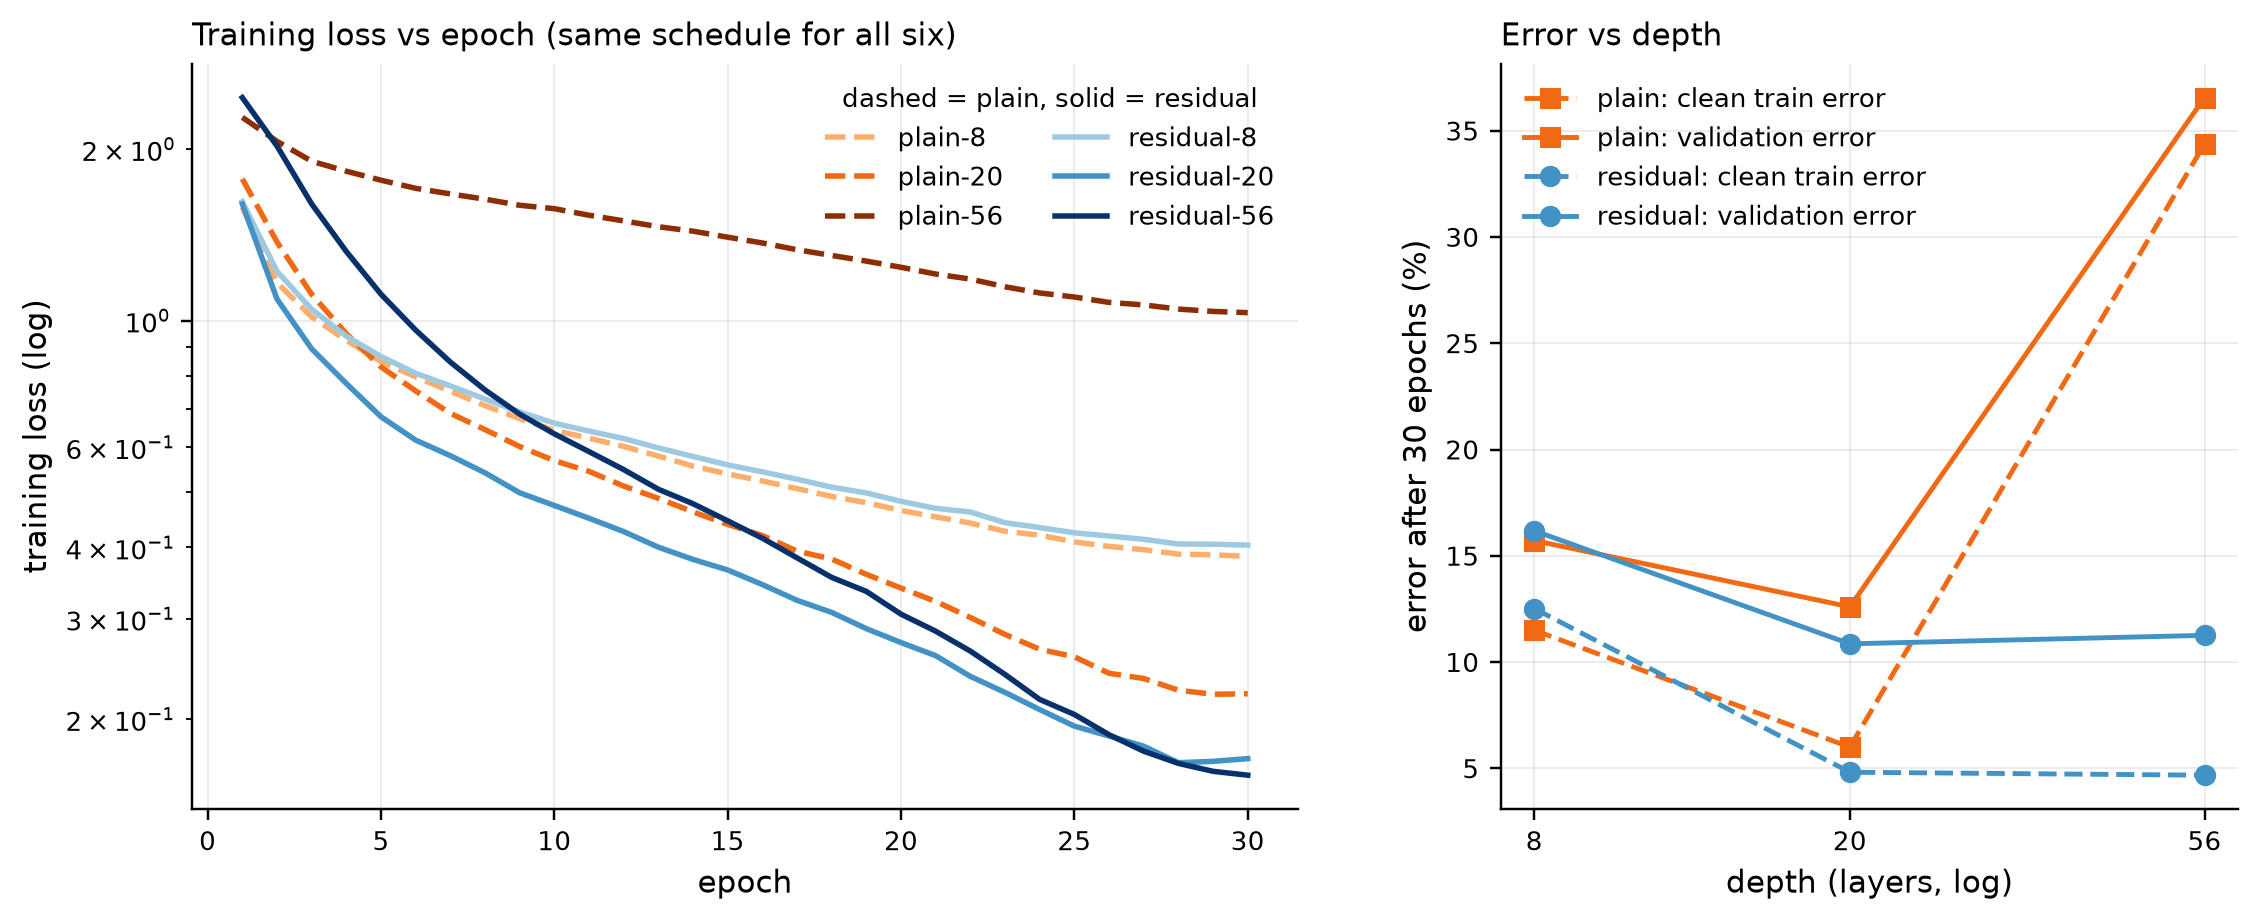

In [27]:
rows = []
for (family, d), h in h3b.items():
    rows.append({"network": f"{family}-{d}", "params": f"{h['params']:,}",
                 "final train loss": h["train_loss"][-1],
                 "clean train acc (%)": 100 * h["train_acc"][-1],
                 "val acc (%)": 100 * h["val_acc"][-1], "s / epoch": np.mean(h["epoch_time"])})
t3b = pd.DataFrame(rows)
display(t3b.style.format({"final train loss": "{:.4f}", "clean train acc (%)": "{:.2f}",
                          "val acc (%)": "{:.2f}", "s / epoch": "{:.1f}"}).hide(axis="index"))

SHADES = {"plain": {8: "#FDAE6B", 20: "#F16913", 56: "#8C2D04"},
          "residual": {8: "#9ECAE1", 20: "#4292C6", 56: "#08306B"}}
ep = np.arange(1, EPOCHS_3B + 1)
fig, (ax_l, ax_d) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.5, 1],
                                                                       "wspace": 0.22})
for (family, d), h in h3b.items():
    ax_l.plot(ep, h["train_loss"], "--" if family == "plain" else "-", color=SHADES[family][d],
              lw=1.8, label=f"{family}-{d}")
ax_l.set_yscale("log")
ax_l.set(xlabel="epoch", ylabel="training loss (log)",
         title="Training loss vs epoch (same schedule for all six)")
ax_l.legend(ncol=2, loc="upper right", title="dashed = plain, solid = residual", title_fontsize=8.5)

for family, mk in (("plain", "s"), ("residual", "o")):
    ds = list(DEPTHS)
    tr_err = [100 * (1 - h3b[(family, d)]["train_acc"][-1]) for d in ds]
    va_err = [100 * (1 - h3b[(family, d)]["val_acc"][-1]) for d in ds]
    col = SHADES[family][20]
    ax_d.plot(ds, tr_err, "--" + mk, color=col, lw=1.6, ms=6, label=f"{family}: clean train error")
    ax_d.plot(ds, va_err, "-" + mk, color=col, lw=1.6, ms=6, label=f"{family}: validation error")
ax_d.set_xscale("log")
ax_d.set_xticks(list(DEPTHS), [str(d) for d in DEPTHS])
ax_d.minorticks_off()
ax_d.set(xlabel="depth (layers, log)", ylabel="error after 30 epochs (%)", title="Error vs depth")
ax_d.legend(loc="upper left")
plt.show()

**Interpretation.** The plain networks show the degradation problem: from 20 to 56 layers the final training loss rises from 0.22 to 1.03 and clean training accuracy falls from 94.00 % to 65.62 % (validation 87.40 % → 63.44 %). Because the *training* error rises, this is an optimisation failure, not overfitting: plain-56 could copy plain-20 and make its extra blocks identities, but SGD does not find that solution. With shortcuts the same depth trains normally; residual-56 has the lowest training loss of all six (0.159) and 88.74 % validation accuracy, 25.3 points above plain-56. The shortcut's "1" gives every block a direct gradient path and makes the identity the default ($F\approx0$), so extra blocks need not make optimisation harder; at depth 8 it barely matters (84.28 % vs 83.82 %). After only 30 epochs (the paper trains about 180), residual-56 has not yet overtaken residual-20 (89.14 %).

## Task 4 · Best CNN with ≤ 500k parameters and ≤ 20 epochs (L08)

**How this works**
- **Model:** ResNet-9 layout at width 16: conv (16) → conv (32) + pool → residual block → conv (64) + pool → conv (128) + pool → residual block → global max-pool → FC (conv = conv-BN-ReLU; residual block = $x+f(x)$, two convs).
- **Base recipe:** 20 epochs, batch 128, SGD with Nesterov momentum 0.9 and weight decay $5\times10^{-4}$; one-cycle learning rate (linear warm-up to $\eta_{\max}=0.1$ over 25 % of steps, then cosine decay); label smoothing $\varepsilon=0.1$; flip + crop + 8×8 cutout, milder than 3(a)'s 16×16 because stacked regularisation underfit there.
- **Ablation on the validation split:** four runs each change one choice (no shortcuts, no cutout, no weight decay, Adam with $\eta_{\max}=2\times10^{-3}$); the best final validation accuracy picks the final model.
- **The test set** is loaded only in this task's last cell, and used once.

In [28]:
def conv_bn(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out),
                         nn.ReLU(inplace=True))

class Residual(nn.Module):
    """x + f(x), f = two conv-BN-ReLU layers; with shortcut=False it is the plain f(x)."""
    def __init__(self, c, shortcut=True):
        super().__init__()
        self.f, self.shortcut = nn.Sequential(conv_bn(c, c), conv_bn(c, c)), shortcut

    def forward(self, x):
        return x + self.f(x) if self.shortcut else self.f(x)

def resnet9(width=16, shortcut=True):
    c = width
    return nn.Sequential(conv_bn(3, c),                                            # 32 x 32
                         conv_bn(c, 2 * c), nn.MaxPool2d(2), Residual(2 * c, shortcut),   # 16 x 16
                         conv_bn(2 * c, 4 * c), nn.MaxPool2d(2),                   # 8 x 8
                         conv_bn(4 * c, 8 * c), nn.MaxPool2d(2), Residual(8 * c, shortcut),  # 4 x 4
                         nn.AdaptiveMaxPool2d(1), nn.Flatten(), nn.Linear(8 * c, 10))

print(f"ResNet-9 (width 16) parameters: {n_params(resnet9()):,}  (limit 500,000)")

EPOCHS_4 = 20
BASE_4 = {"shortcut": True, "cutout": True, "wd": 5e-4, "opt": "SGD"}
T4_RUNS = {"base": {}, "no shortcuts": {"shortcut": False}, "no cutout": {"cutout": False},
           "no weight decay": {"wd": 0.0}, "Adam instead of SGD": {"opt": "Adam"}}

def one_cycle(max_lr):
    return lambda opt, total: torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=max_lr, total_steps=total, pct_start=0.25, cycle_momentum=False)

def run_t4(run_name):
    cfg = {**BASE_4, **T4_RUNS[run_name]}
    if cfg["opt"] == "SGD":
        make_opt = lambda ps: torch.optim.SGD(ps, lr=0.1, momentum=0.9, nesterov=True,
                                              weight_decay=cfg["wd"])
        sched = one_cycle(0.1)
    else:
        make_opt = lambda ps: torch.optim.Adam(ps, lr=2e-3, weight_decay=cfg["wd"])
        sched = one_cycle(2e-3)
    aug = (lambda x: cutout(flip_crop(x), size=8)) if cfg["cutout"] else flip_crop
    return run_experiment(f"task4_{run_name.replace(' ', '_')}",
                          lambda: resnet9(16, cfg["shortcut"]), make_opt, EPOCHS_4,
                          make_sched=sched, augment=aug, label_smoothing=0.1, save_model=True,
                          log_every=10)

h4 = {name: run_t4(name) for name in T4_RUNS}

ResNet-9 (width 16) parameters: 412,954  (limit 500,000)


task4_base | epoch   1/20 | train loss 1.6537 | val loss 1.5883 | val acc 46.86% | 7.4 s/epoch


task4_base | epoch  10/20 | train loss 0.9446 | val loss 0.8204 | val acc 73.50% | 5.8 s/epoch


task4_base | epoch  20/20 | train loss 0.7285 | val loss 0.3844 | val acc 89.48% | 3.6 s/epoch


task4_no_shortcuts | epoch   1/20 | train loss 1.6291 | val loss 1.2068 | val acc 57.62% | 3.7 s/epoch


...

task4_no_weight_decay | epoch  10/20 | train loss 0.8906 | val loss 0.5871 | val acc 81.60% | 3.6 s/epoch


task4_no_weight_decay | epoch  20/20 | train loss 0.7500 | val loss 0.4080 | val acc 88.86% | 3.6 s/epoch


task4_Adam_instead_of_SGD | epoch   1/20 | train loss 1.8059 | val loss 1.4474 | val acc 48.54% | 3.8 s/epoch


task4_Adam_instead_of_SGD | epoch  10/20 | train loss 0.9576 | val loss 0.5961 | val acc 81.12% | 4.7 s/epoch


task4_Adam_instead_of_SGD | epoch  20/20 | train loss 0.7484 | val loss 0.4034 | val acc 88.60% | 6.7 s/epoch


run,params,final val acc (%),Δ vs base (pts),best val acc (%),final train loss,s / epoch
base,"412,954",89.48,+0.00,89.48,0.7285,5.3
no shortcuts,"412,954",89.46,-0.02,89.62,0.7307,5.2
no cutout,"412,954",89.86,+0.38,89.94,0.6747,5.5
no weight decay,"412,954",88.86,-0.62,88.98,0.7500,3.8
Adam instead of SGD,"412,954",88.60,-0.88,88.60,0.7484,5.5


final model (best final validation accuracy): no cutout


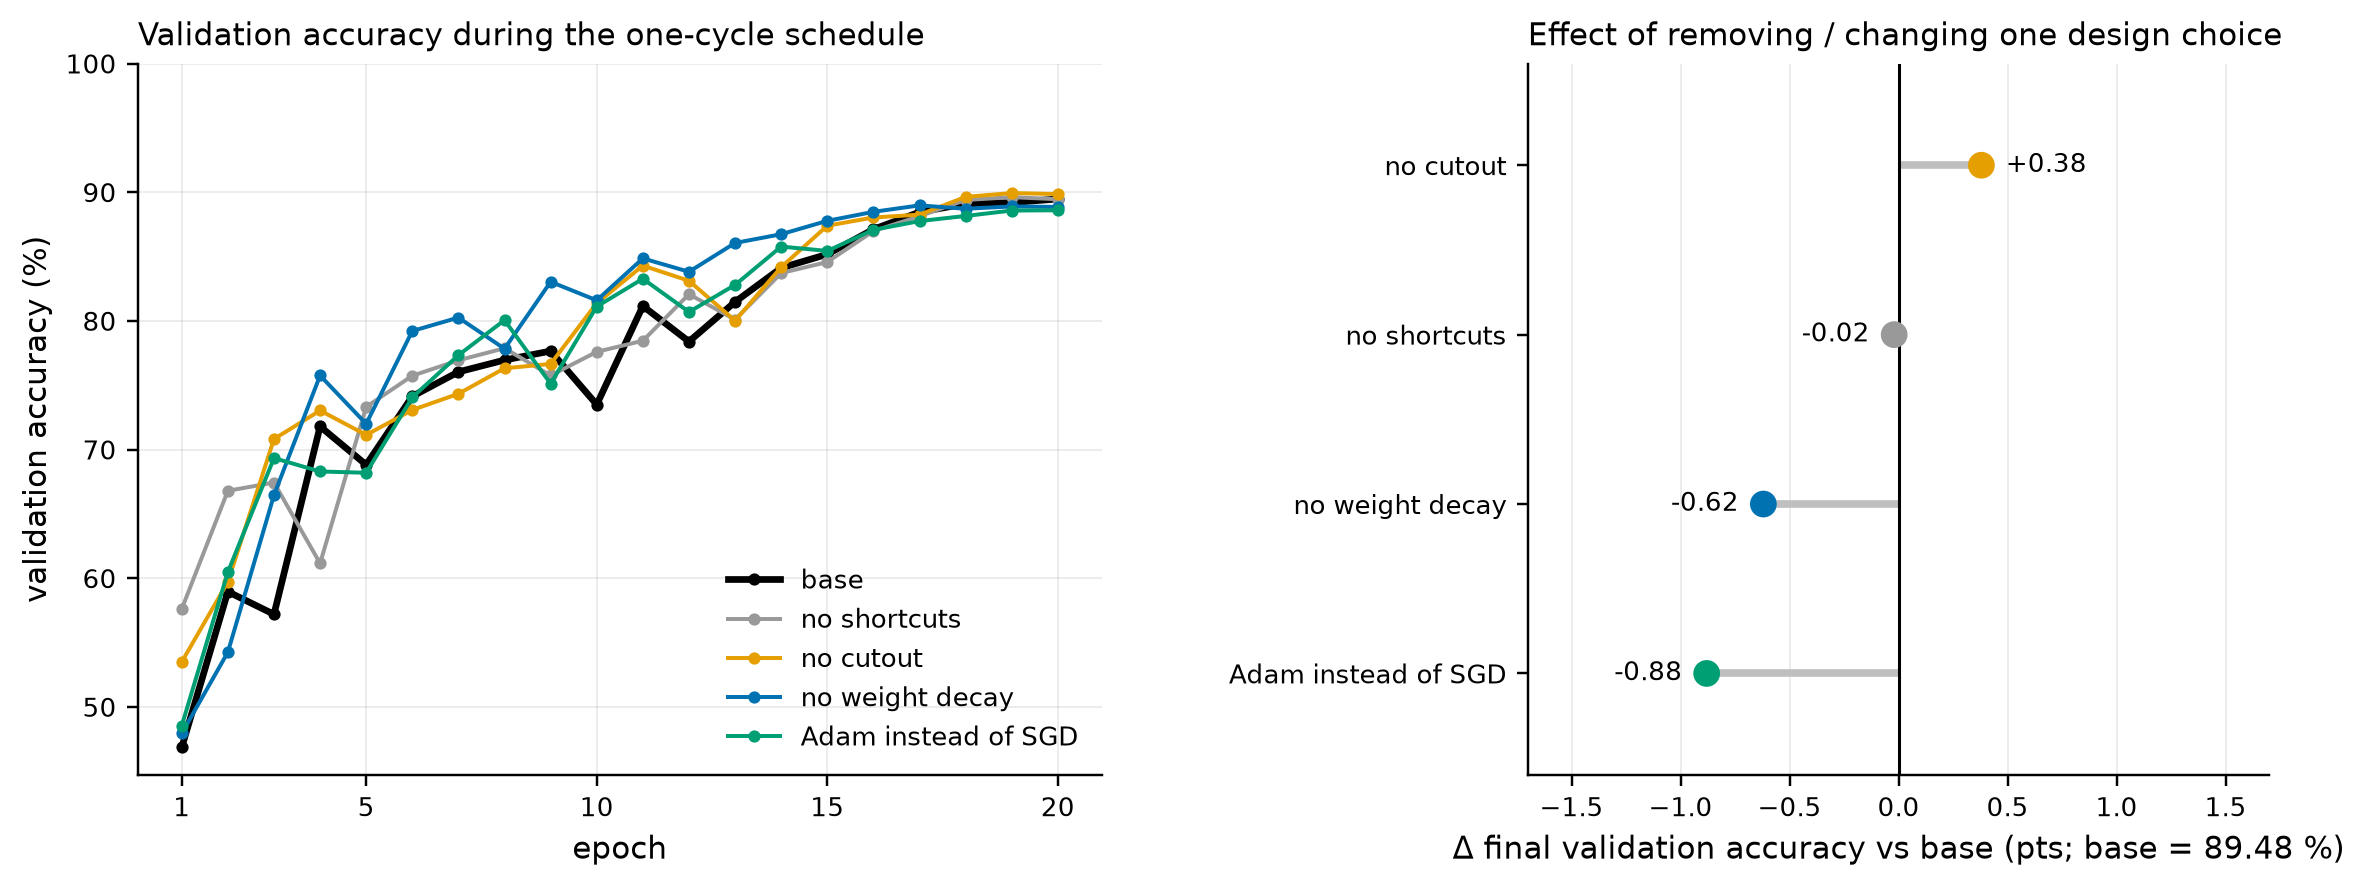

In [29]:
base_va = 100 * h4["base"]["val_acc"][-1]
t4 = pd.DataFrame([{"run": name, "params": f"{h['params']:,}",
                    "final val acc (%)": 100 * h["val_acc"][-1],
                    "Δ vs base (pts)": 100 * h["val_acc"][-1] - base_va,
                    "best val acc (%)": 100 * max(h["val_acc"]),
                    "final train loss": h["train_loss"][-1], "s / epoch": np.mean(h["epoch_time"])}
                   for name, h in h4.items()])
display(t4.style.format({"final val acc (%)": "{:.2f}", "Δ vs base (pts)": "{:+.2f}",
                         "best val acc (%)": "{:.2f}", "final train loss": "{:.4f}",
                         "s / epoch": "{:.1f}"}).hide(axis="index"))
FINAL_4 = t4.loc[t4["final val acc (%)"].idxmax(), "run"]
print(f"final model (best final validation accuracy): {FINAL_4}")

T4_COL = {"base": "black", "no shortcuts": "#999999", "no cutout": "#E69F00",
          "no weight decay": "#0072B2", "Adam instead of SGD": "#009E73"}
fig, (ax_c, ax_d) = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.3, 1],
                                                                        "wspace": 0.5})
ep = np.arange(1, EPOCHS_4 + 1)
for name, h in h4.items():
    ax_c.plot(ep, 100 * np.array(h["val_acc"]), "-o", ms=3, color=T4_COL[name],
              lw=2.2 if name == "base" else 1.3, label=name)
ax_c.set(xlabel="epoch", ylabel="validation accuracy (%)",
         title="Validation accuracy during the one-cycle schedule")
ax_c.set_ylim(max(0, ax_c.get_ylim()[0]), 100)
ax_c.set_xticks([1, 5, 10, 15, 20])
ax_c.legend(loc="lower right")

abl = t4[t4.run != "base"].sort_values("Δ vs base (pts)")
ypos = np.arange(len(abl))
ax_d.hlines(ypos, 0, abl["Δ vs base (pts)"], color="0.75", lw=2.5)
ax_d.scatter(abl["Δ vs base (pts)"], ypos, color=[T4_COL[r] for r in abl.run], s=60, zorder=3)
for y, (_, r) in zip(ypos, abl.iterrows()):
    d = r["Δ vs base (pts)"]
    ax_d.annotate(f"{d:+.2f}", (d, y), xytext=(8 if d >= 0 else -8, 0), textcoords="offset points",
                  ha="left" if d >= 0 else "right", va="center", fontsize=8.5)
ax_d.axvline(0, color="black", lw=1)
ax_d.set_yticks(ypos, abl.run); ax_d.grid(axis="y", visible=False)
lim = 1.7 * max(1.0, abl["Δ vs base (pts)"].abs().max())
ax_d.set(xlim=(-lim, lim), ylim=(-0.6, len(abl) - 0.4))
ax_d.set(xlabel=f"Δ final validation accuracy vs base (pts; base = {base_va:.2f} %)",
         title="Effect of removing / changing one design choice")
plt.show()

**Interpretation.** The base recipe reaches 89.48 % validation accuracy with 412,954 parameters in 20 epochs, on par with residual-20 from 3(b) (89.14 % in 30 epochs). Removing the shortcuts changes almost nothing (−0.02), as 3(b) predicts for a network only 8 conv layers deep. Dropping weight decay (−0.62) and switching to Adam (−0.88, at one untuned $\eta_{\max}$) cost the most; in Adam the L2 gradient $\lambda\theta$ is divided by $\sqrt{\hat v}$, so weights with large gradients are decayed less, the coupling AdamW removes. Removing cutout gives +0.38 and a lower training loss (0.6747 vs 0.7285), consistent with 3(a)'s finding that extra regularisation slows fitting on a short budget. With a single seed, this and the shortcut difference are within the 0.09–0.44-point seed spread seen in 3(a). Following the protocol, "no cutout" (89.86 %) becomes the final model.

### Final evaluation on the test set (used exactly once)

**How this works:** the CIFAR-10 test set is loaded here for the first time and normalised with the *training-split* statistics. The final model's saved weights get a single evaluation pass. That pass gives both the test accuracy and the confusion matrix, so no choice in this notebook depends on the test result.

Files already downloaded and verified


final model: no cutout | 412,954 parameters | validation 89.86 % | TEST ACCURACY 89.67 % (8967 / 10000)


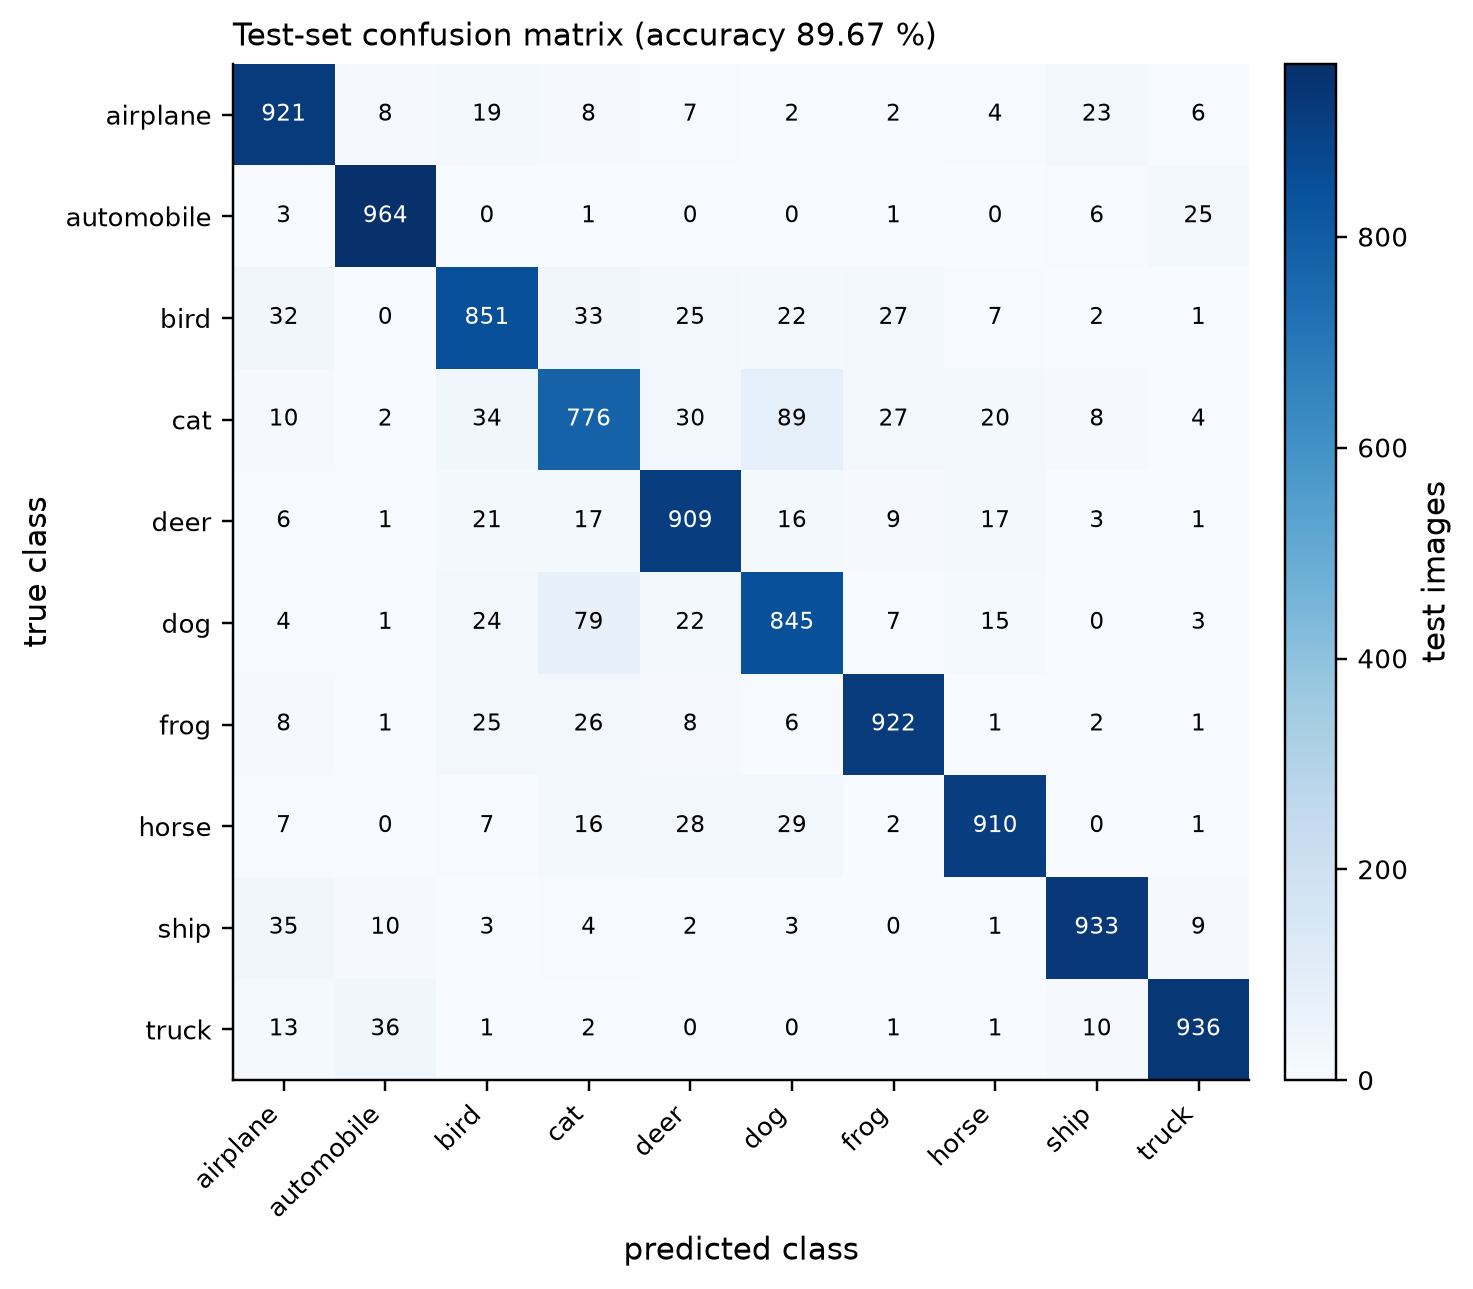

per-class test accuracy (%): {'airplane': 92.1, 'automobile': 96.4, 'bird': 85.1, 'cat': 77.6, 'deer': 90.9, 'dog': 84.5, 'frog': 92.2, 'horse': 91.0, 'ship': 93.3, 'truck': 93.6}


In [30]:
test_set = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)   # first and only use
X_te = normalize(torch.from_numpy(test_set.data).permute(0, 3, 1, 2)).to(DEVICE)
y_te = torch.tensor(test_set.targets, device=DEVICE)

final_model = resnet9(16, {**BASE_4, **T4_RUNS[FINAL_4]}["shortcut"]).to(DEVICE)
final_model.load_state_dict(torch.load(CKPT_DIR / f"task4_{FINAL_4.replace(' ', '_')}.pt",
                                       map_location=DEVICE, weights_only=True))
final_model.eval()
with torch.no_grad(), torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
    pred = torch.cat([final_model(xb).argmax(1) for xb, _ in batches(X_te, y_te, 1000)])
test_acc = (pred == y_te).float().mean().item()
print(f"final model: {FINAL_4} | {n_params(final_model):,} parameters | "
      f"validation {100 * h4[FINAL_4]['val_acc'][-1]:.2f} % | TEST ACCURACY {100 * test_acc:.2f} % "
      f"({int((pred == y_te).sum())} / {len(y_te)})")

cm = torch.zeros(10, 10, dtype=torch.long)
cm.index_put_((y_te.cpu(), pred.cpu()), torch.ones(len(y_te), dtype=torch.long), accumulate=True)
cm = cm.numpy()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7.5,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right"); ax.set_yticks(range(10), CLASSES)
ax.set(xlabel="predicted class", ylabel="true class",
       title=f"Test-set confusion matrix (accuracy {100 * test_acc:.2f} %)")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label="test images")
plt.show()
per_class = 100 * cm.diagonal() / cm.sum(1)
print("per-class test accuracy (%):", {c: round(float(a), 1) for c, a in zip(CLASSES, per_class)})

**Interpretation.** The final model scores 89.67 % on the test set, 0.19 points below its validation accuracy (89.86 %). That is the expected slight optimism from picking the best of five runs on the validation split, so validation was a reliable guide. The 1,033 errors concentrate on visually similar pairs: cat is the weakest class (77.6 %), and cat ↔ dog confusions alone account for 168 errors (16 %). Next come bird ↔ cat (67), truck ↔ automobile (61) and ship ↔ airplane (58), pairs that share shape, texture or sky and water backgrounds at 32×32. Classes with distinctive shapes are easiest: automobile (96.4 %), truck (93.6 %) and ship (93.3 %).